In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sc
import sklearn as sk
import seaborn as sns
%matplotlib inline

# For Filtering the warnings
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df_ncd = pd.read_csv('/content/bgd2018.csv')

In [ ]:
df_ncd.head()

,pid,psu,stratum,division,urbanrural,wstep1,wstep2,wstep3,agerange,sex,...,b5,b6,b8,b9,b10,b14,b15,b16,b17,ldl
0,E11-1-1,1,102,1,Urban,2289.934326,2289.934326,2225.452881,18-29,0,...,97.0,NaN,179.0,NaN,2.0,37.599998,30.0,105.0,37.0,121.000000
1,E11-10-1,1,102,1,Urban,1202.908813,1202.908813,NaN,45-59,0,...,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E11-100-1,48,101,1,Rural,7604.362305,7604.362305,12915.715820,30-44,0,...,100.0,NaN,168.0,NaN,2.0,21.000000,15.0,140.0,29.0,111.000000
3,E11-101-1,49,101,1,Rural,7710.941895,7710.941895,7493.812012,18-29,0,...,90.0,NaN,134.0,NaN,2.0,29.000000,20.0,68.0,43.0,77.400002
4,E11-102-1,49,101,1,Rural,4049.076172,4049.076172,6877.199219,30-44,0,...,99.0,NaN,231.0,NaN,2.0,235.000000,120.0,235.0,33.0,151.000000


In [ ]:
df_ncd.shape

(8185, 425)

In [ ]:
columns_to_keep = ['c5', 'division', 'urbanrural', 'sex', 'age', 'c4', 'c7', 'c8', 't1', 't2', 't3', 't8', 't9', 'a4', 'dx6', 'p7', 'p9a', 'h2a', 'h7a', 'h17', 'h20a', 'h20e', 'm11', 'm12', 'm16b', 'b5', 'b8', 'b16', 'b17', 'ldl']

df_ncd = df_ncd[columns_to_keep]

In [ ]:
df_ncd.rename(columns={'c5': 'education', 'c4': 'yrs of education', 'c7': 'marital_status', 'c8': 'work_status', 't1': 'current smoking', 't2': 'current daily smoking', 't3': 'age started smoking', 't8': 'past smoking', 't9': 'past daily smoking', 'a4': 'freq drinking in past 12 mos', 'dx6': 'oil used most often', 'p7': 'active transport', 'p9a': 'active transport hours per day', 'h2a': 'told had high BP', 'h7a': 'told had high gluc', 'h17': 'had heart attack or stroke', 'h20a': 'advised to not smoke', 'h20e': 'advised to do pa', 'm11': 'height', 'm12': 'weight', 'm16b': 'heart rate', 'b5': 'fasting blood glucose', 'b8': 'cholesterol', 'b16':'triglycerides', 'b17': 'hdl'}, inplace=True)


In [ ]:
df_ncd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8185 entries, 0 to 8184
Data columns (total 30 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   education                       8185 non-null   int64  
 1   division                        8185 non-null   int64  
 2   urbanrural                      8185 non-null   object 
 3   sex                             8185 non-null   int64  
 4   age                             8185 non-null   int64  
 5   yrs of education                8185 non-null   int64  
 6   marital_status                  8185 non-null   int64  
 7   work_status                     8185 non-null   int64  
 8   current smoking                 8185 non-null   int64  
 9   current daily smoking           1923 non-null   float64
 10  age started smoking             1923 non-null   float64
 11  past smoking                    6262 non-null   float64
 12  past daily smoking              71

In [ ]:
pd.set_option('display.float_format', lambda x: '%.3f' % x)
df_ncd.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
education,8185.000,2.931,4.589,1.000,1.000,3.000,3.000,88.000
division,8185.000,4.510,2.280,1.000,3.000,5.000,6.000,8.000
sex,8185.000,0.465,0.499,0.000,0.000,0.000,1.000,1.000
age,8185.000,39.075,12.300,18.000,30.000,38.000,48.000,69.000
yrs of education,8185.000,9.870,17.467,0.000,1.000,5.000,10.000,88.000
marital_status,8185.000,2.068,0.668,1.000,2.000,2.000,2.000,5.000
work_status,8185.000,8.981,4.402,1.000,5.000,12.000,12.000,88.000
current smoking,8185.000,1.765,0.424,1.000,2.000,2.000,2.000,2.000
current daily smoking,1923.000,1.046,0.210,1.000,1.000,1.000,1.000,2.000
age started smoking,1923.000,18.252,7.105,8.000,15.000,17.000,20.000,77.000


2. Filtering Dataset

In [ ]:
df_ncd.shape

(8185, 30)

In [ ]:
df_ncd.isnull()

,education,division,urbanrural,sex,age,yrs of education,marital_status,work_status,current smoking,current daily smoking,...,advised to not smoke,advised to do pa,height,weight,heart rate,fasting blood glucose,cholesterol,triglycerides,hdl,ldl
0,False,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,True,True,True,True,True
2,False,False,False,False,False,False,False,False,False,True,...,True,True,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,True,...,True,True,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,True,...,True,True,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8180,False,False,False,False,False,False,False,False,False,False,...,True,True,False,False,False,False,False,False,False,False
8181,False,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
8182,False,False,False,False,False,False,False,False,False,False,...,True,True,False,False,False,False,False,False,False,False
8183,False,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
df_ncd.isnull().sum()/len(df_ncd)*100

,0
education,0.000
division,0.000
urbanrural,0.000
sex,0.000
age,0.000
yrs of education,0.000
marital_status,0.000
work_status,0.000
current smoking,0.000
current daily smoking,76.506


In [ ]:
import missingno as msno

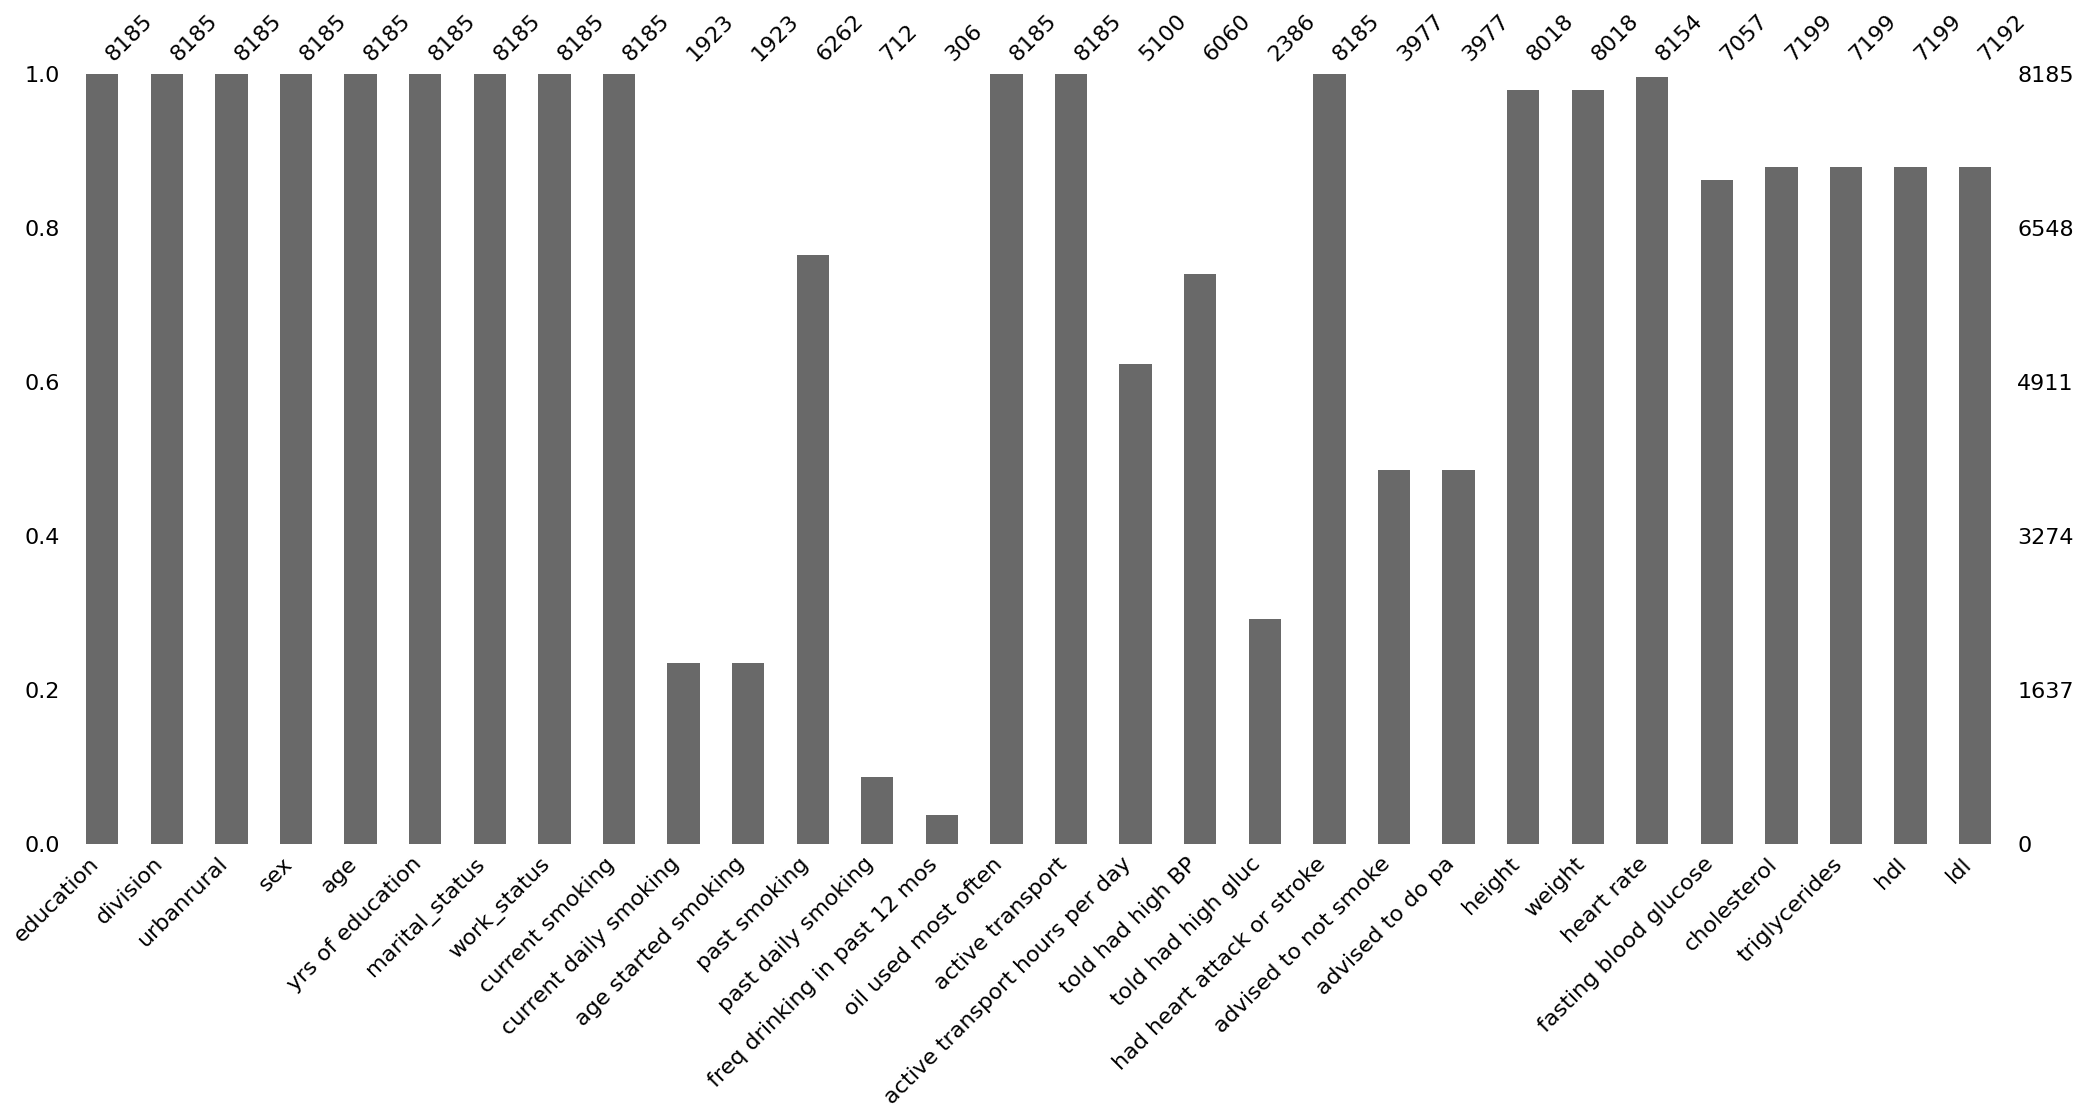

In [ ]:
msno.bar(df_ncd)
plt.show()

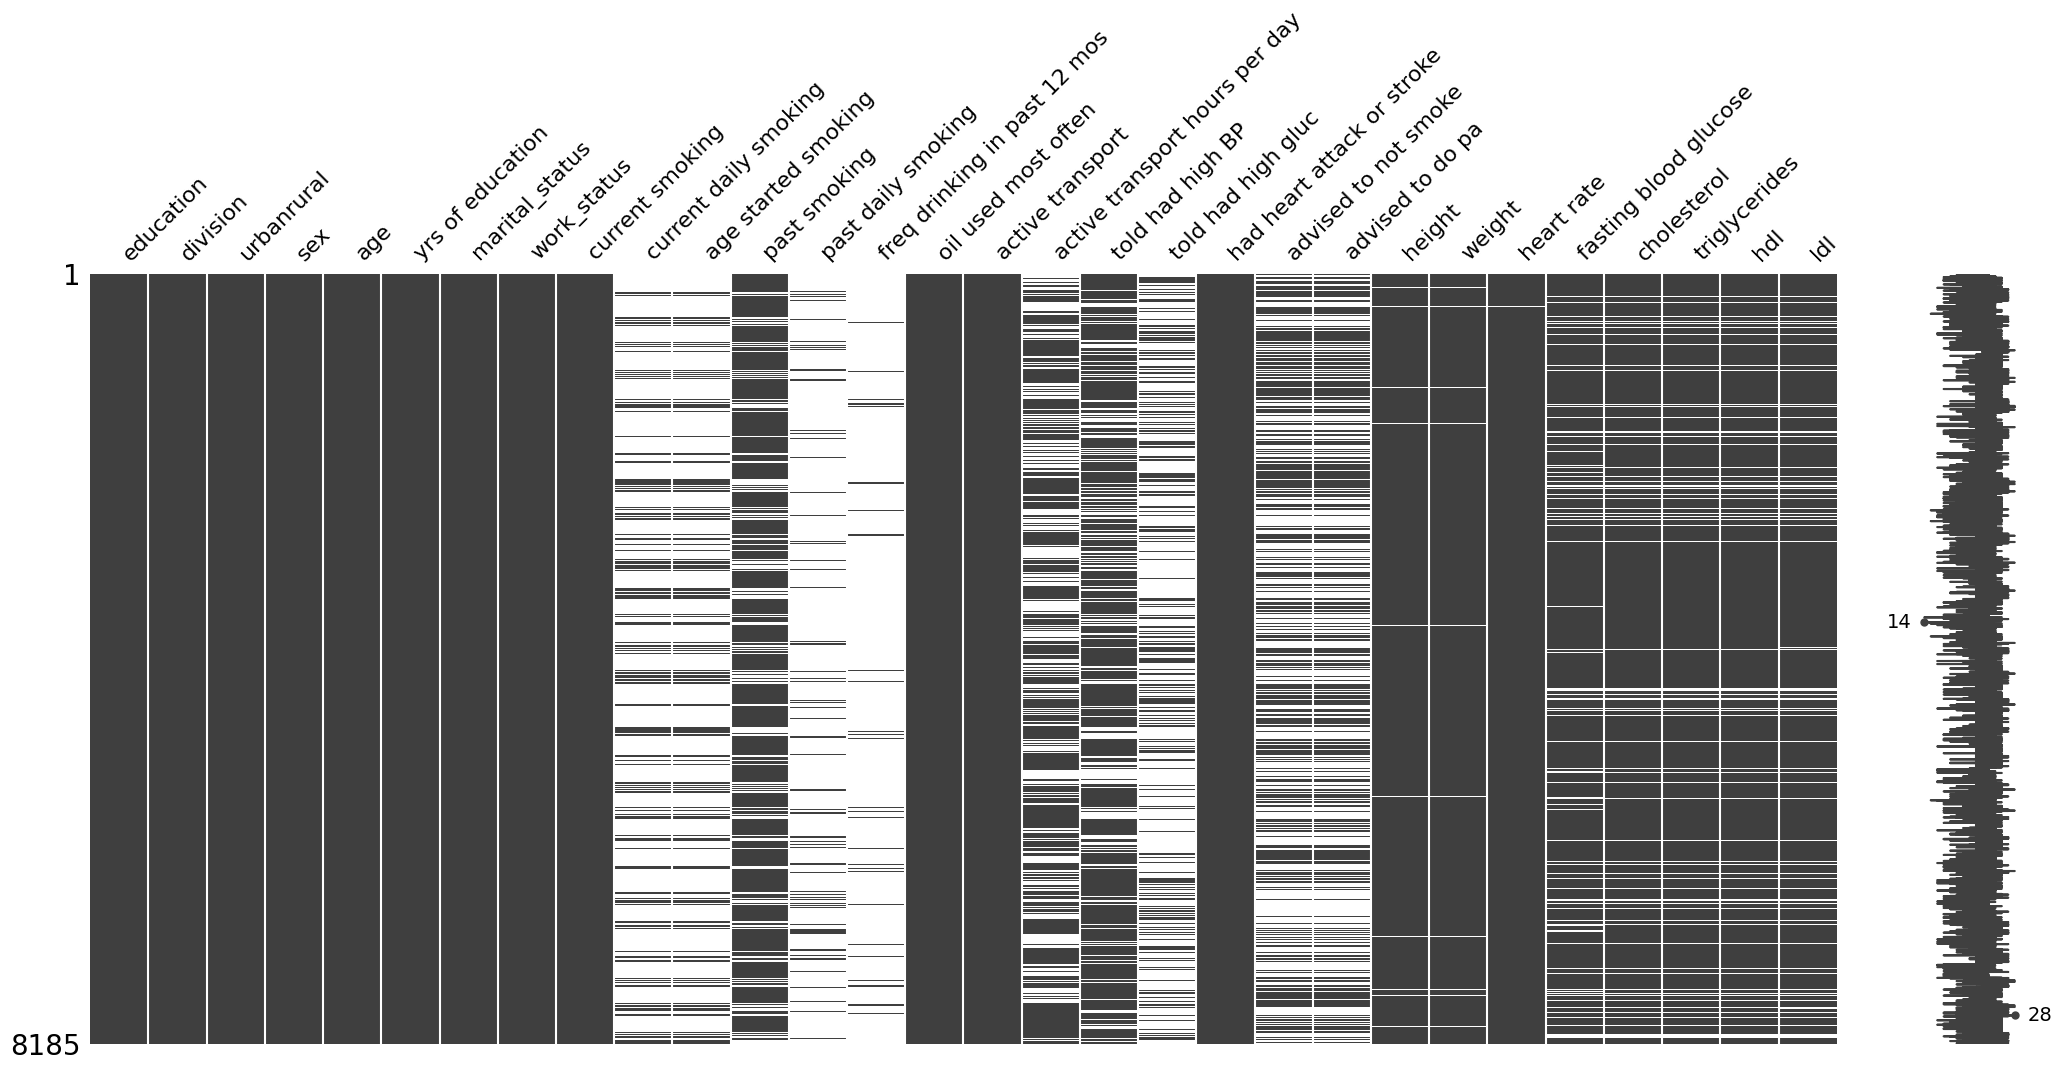

In [ ]:
msno.matrix(df_ncd)
plt.show()

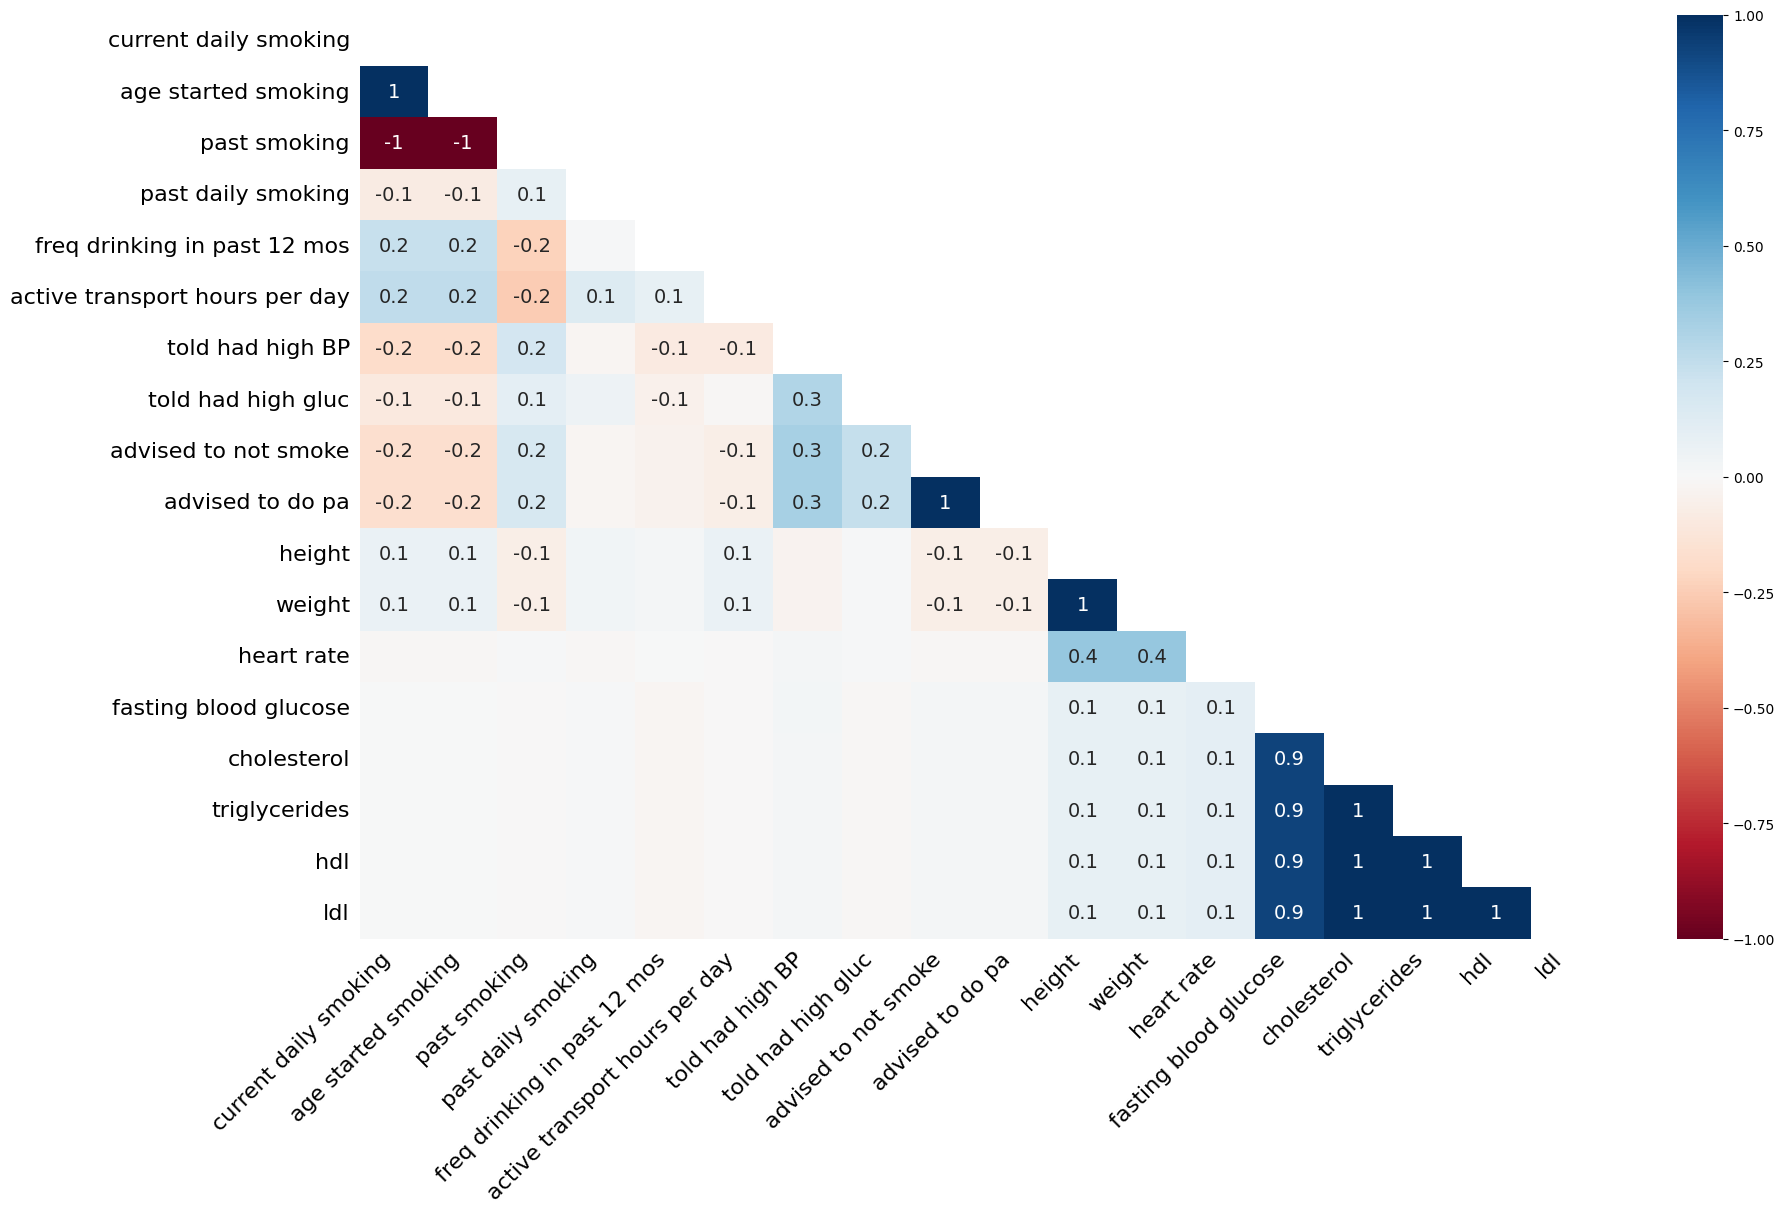

In [ ]:
msno.heatmap(df_ncd)
plt.show()

In [ ]:
# List of columns where you want to input 0 for missing values
columns_to_fill_zero = ['current daily smoking', 'past smoking', 'past daily smoking', 'told had high BP', 'told had high gluc', 'advised to do pa', 'advised to not smoke' ]  # Replace with your actual column names

# Fill missing values (NaN) with 0 in the specified columns
df_ncd[columns_to_fill_zero] = df_ncd[columns_to_fill_zero].fillna(0)

# Show the updated data to verify
print(df_ncd[columns_to_fill_zero].isnull().sum())  # Check if there are any remaining NaN values



current daily smoking    0
past smoking             0
past daily smoking       0
told had high BP         0
told had high gluc       0
advised to do pa         0
advised to not smoke     0
dtype: int64


In [ ]:
# List of columns where you want to replace missing values with the mean
columns_to_fill_mean = ['age started smoking', 'freq drinking in past 12 mos', 'active transport hours per day', 'triglycerides', 'height', 'weight', 'heart rate',
                        'cholesterol', 'hdl', 'ldl', 'fasting blood glucose']

# Replace missing values with the mean for each specified column
for column in columns_to_fill_mean:
    df_ncd[column] = df_ncd[column].fillna(df_ncd[column].mean())

# Verify by checking if there are still any missing values in these columns
print(df_ncd[columns_to_fill_mean].isnull().sum())  # Should return 0 for all

age started smoking               0
freq drinking in past 12 mos      0
active transport hours per day    0
triglycerides                     0
height                            0
weight                            0
heart rate                        0
cholesterol                       0
hdl                               0
ldl                               0
fasting blood glucose             0
dtype: int64


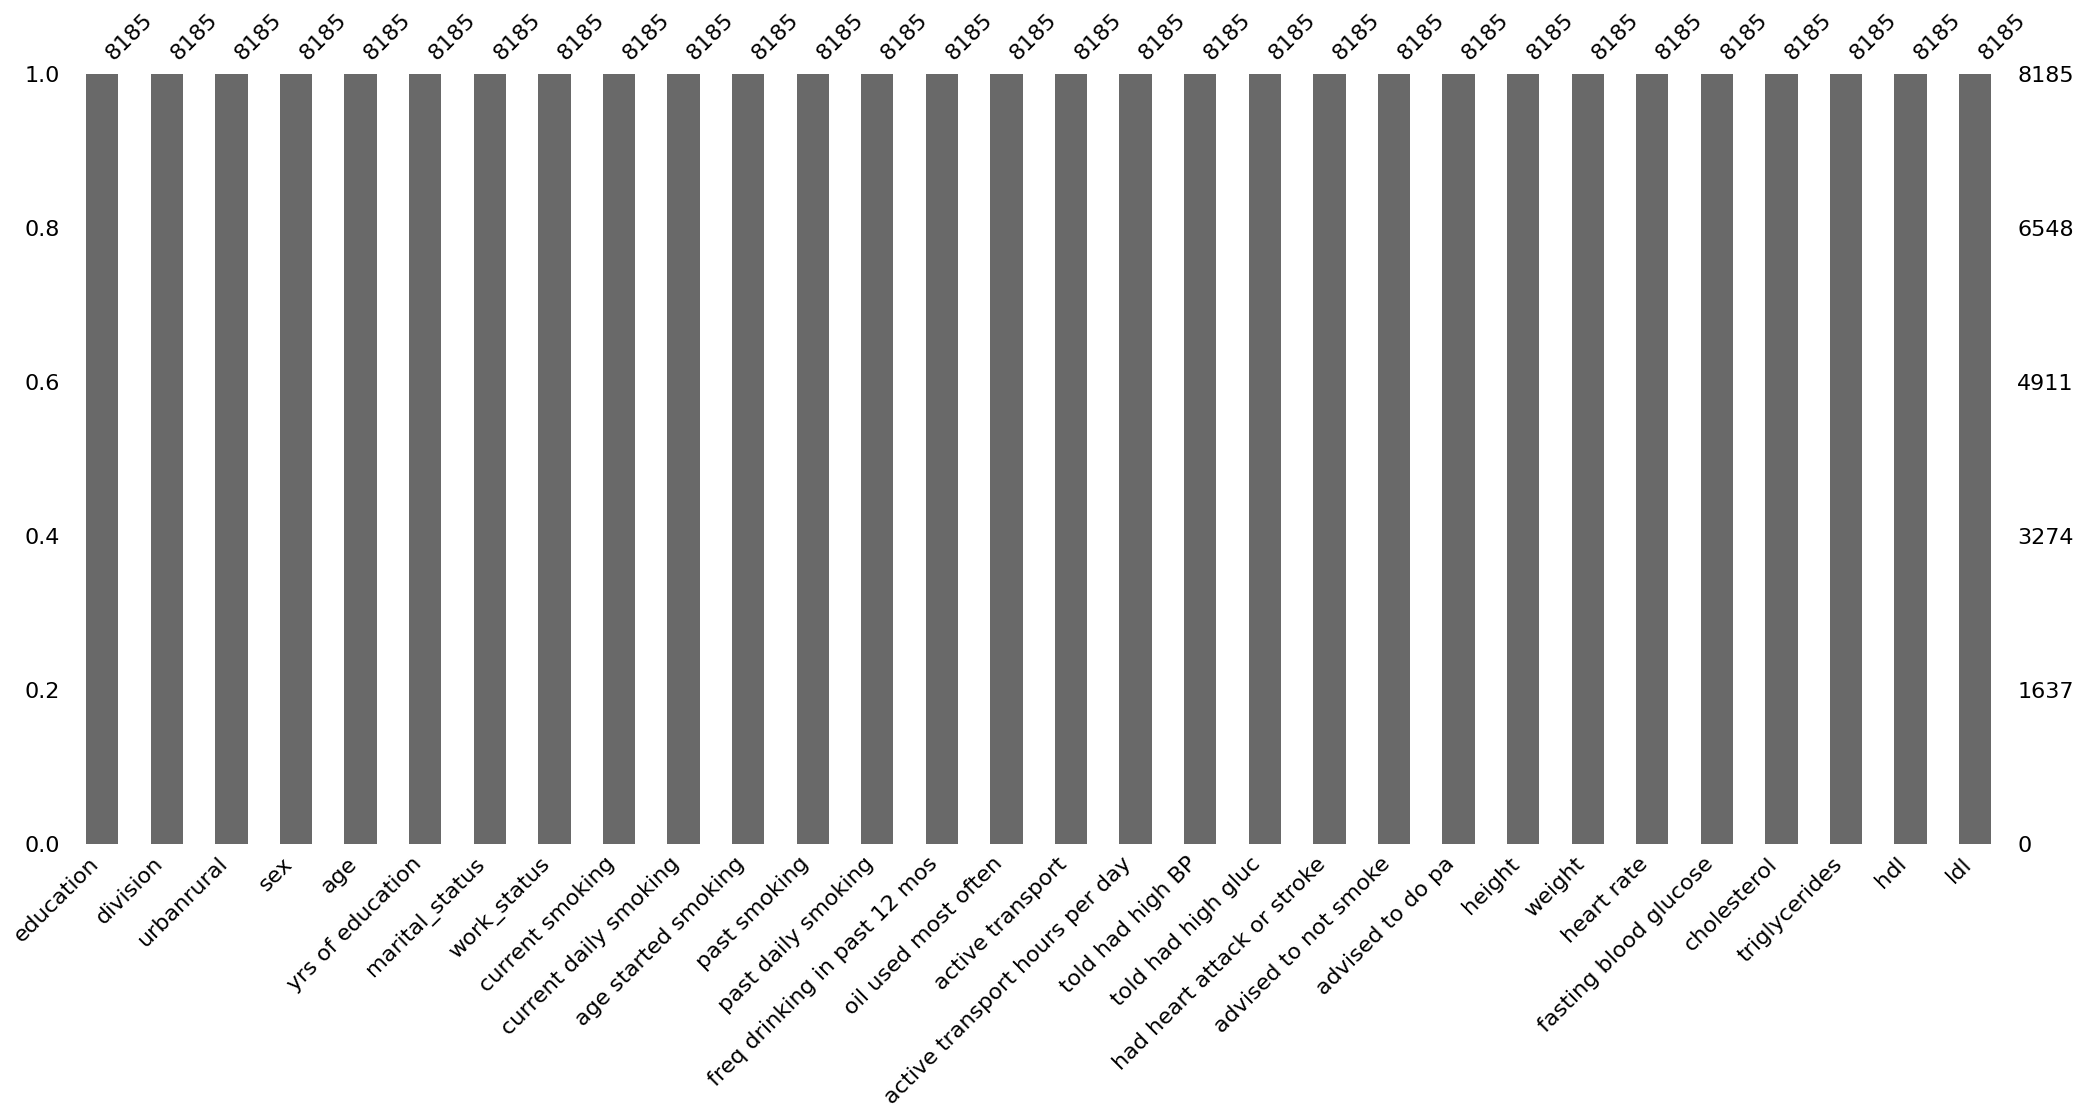

In [ ]:
msno.bar(df_ncd)
plt.show()

In [ ]:
(df_ncd.isnull().sum())*100/len(df_ncd)

,0
education,0.000
division,0.000
urbanrural,0.000
sex,0.000
age,0.000
yrs of education,0.000
marital_status,0.000
work_status,0.000
current smoking,0.000
current daily smoking,0.000


In [ ]:
df_ncd.duplicated().sum()

0

In [ ]:
pip install pandas seaborn matplotlib


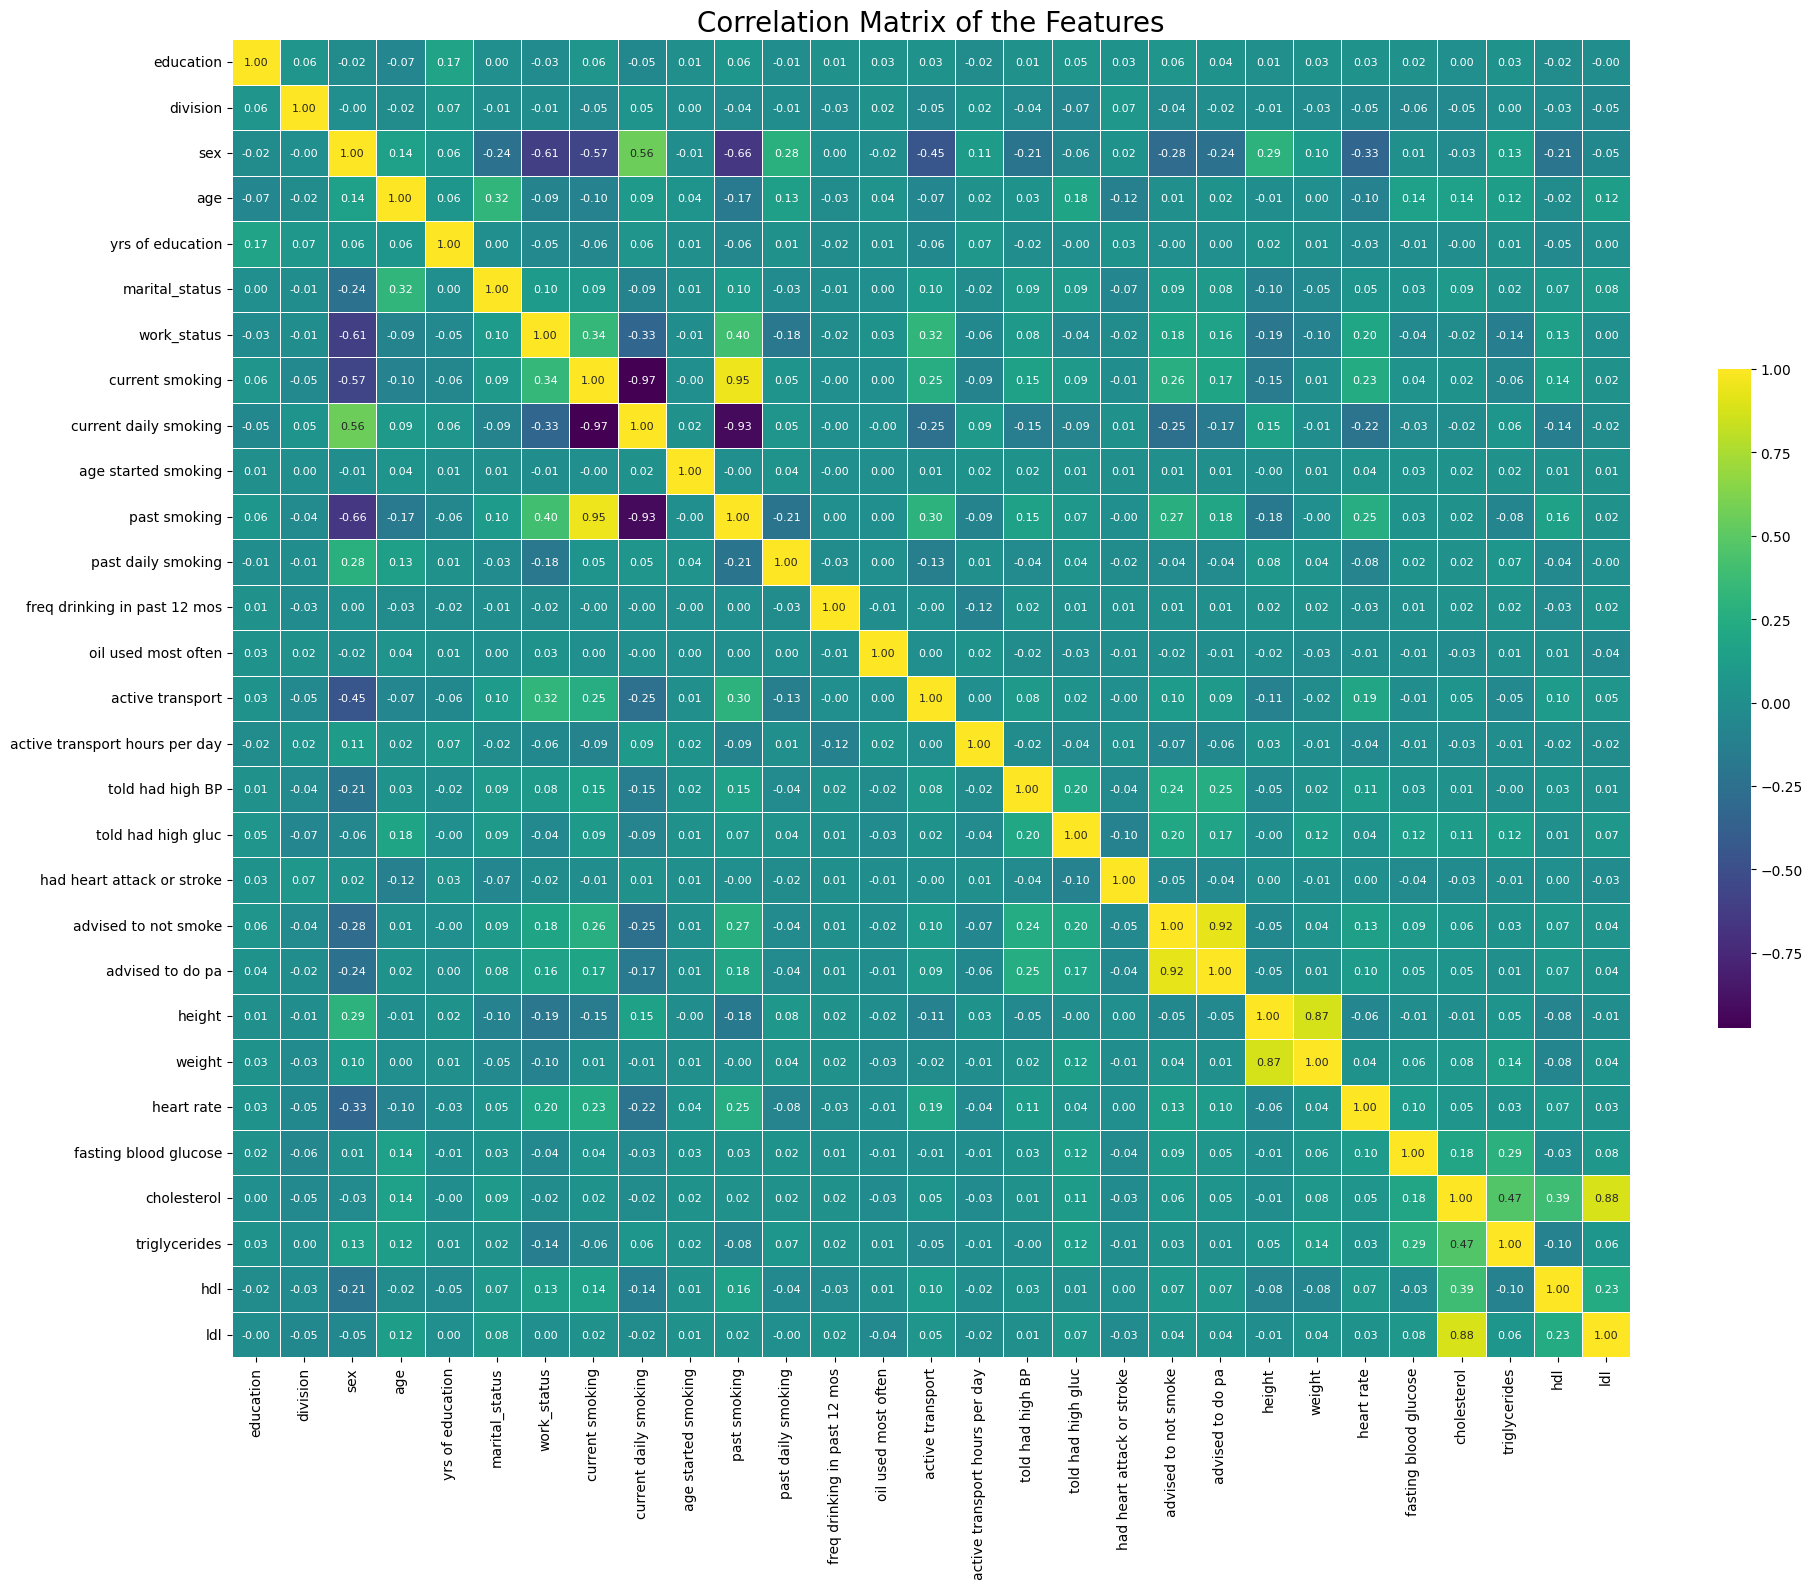

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the correlation matrix
df = df_ncd
# Select only numerical columns for correlation calculation
numerical_df = df.select_dtypes(include=['number'])
correlation_matrix = numerical_df.corr()

# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(20, 16))
heatmap = sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='viridis', linewidths=0.5, cbar_kws={'shrink': .5}, annot_kws={"size": 8})
plt.title('Correlation Matrix of the Features', fontsize=20)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()  # Adjust layout to ensure everything fits without overlap
plt.show()

In [ ]:
df_ncd.shape

(8185, 30)

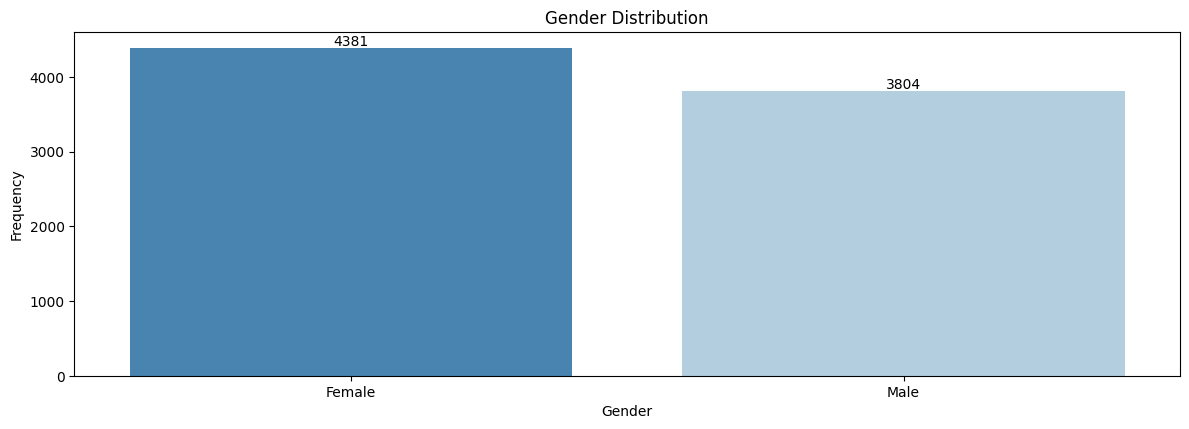

In [ ]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Renaming 'sex' column values for clarity (0: Female, 1: Male)
df_ncd['sex'] = df_ncd['sex'].replace({0: 'Female', 1: 'Male'})

# Function to annotate bars with counts
def annotate_barplot(ax):
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black')

# Plotting the bar charts similar to the image layout
plt.figure(figsize=(12, 12))

# 1. Gender distribution
plt.subplot(3, 1, 1)
ax1 = sns.countplot(x='sex', data=df_ncd, palette='Blues_r')
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Frequency')
annotate_barplot(ax1)

# Adjust layout for better presentation
plt.tight_layout()
plt.show()


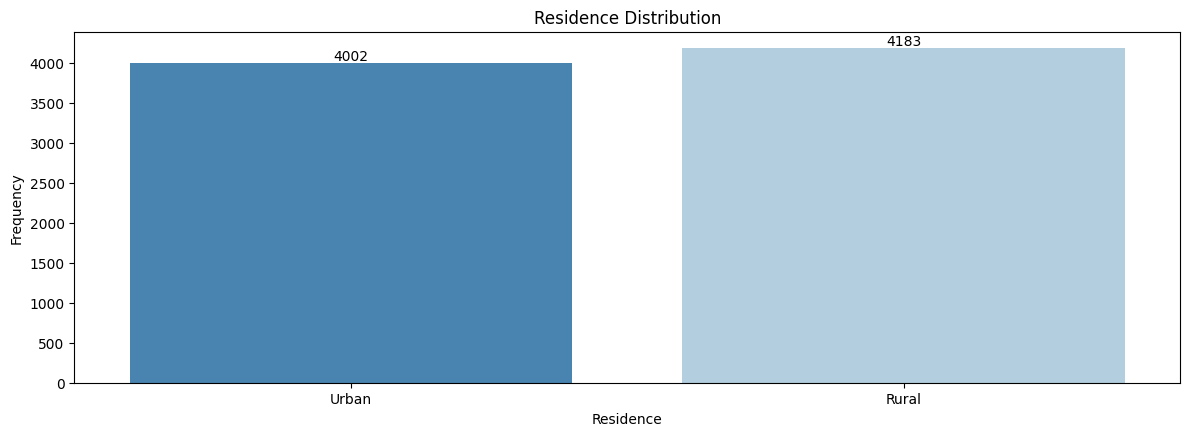

In [ ]:

# Function to annotate bars with counts
def annotate_barplot(ax):
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black')

# Plotting the bar charts similar to the image layout
plt.figure(figsize=(12, 12))

# 2. Urban vs Rural distribution
plt.subplot(3, 1, 2)
ax2 = sns.countplot(x='urbanrural', data=df_ncd, palette='Blues_r')
plt.title('Residence Distribution')
plt.xlabel('Residence')
plt.ylabel('Frequency')
annotate_barplot(ax2)

# Adjust layout for better presentation
plt.tight_layout()
plt.show()

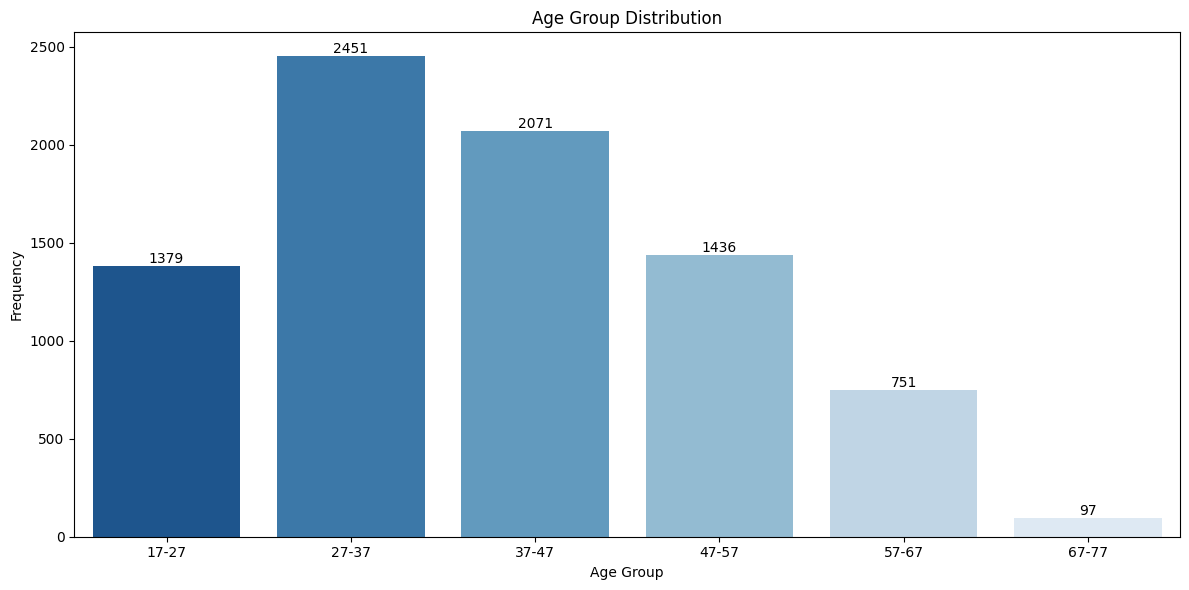

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create age bins (17-27, 27-37, etc.) and add a new 'age_group' column
age_bins = [17, 27, 37, 47, 57, 67, 77]
age_labels = ['17-27', '27-37', '37-47', '47-57', '57-67', '67-77']
df_ncd['age_group'] = pd.cut(df_ncd['age'], bins=age_bins, labels=age_labels, right=False)

# Function to annotate bars with counts
def annotate_barplot(ax):
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black')

# Plotting the bar chart for age group distribution
plt.figure(figsize=(12, 6))

# Age group distribution
ax = sns.countplot(x='age_group', data=df_ncd, palette='Blues_r')
plt.title('Age Group Distribution')
plt.xlabel('Age Group')
plt.ylabel('Frequency')
annotate_barplot(ax)

# Adjust layout for better presentation
plt.tight_layout()
plt.show()


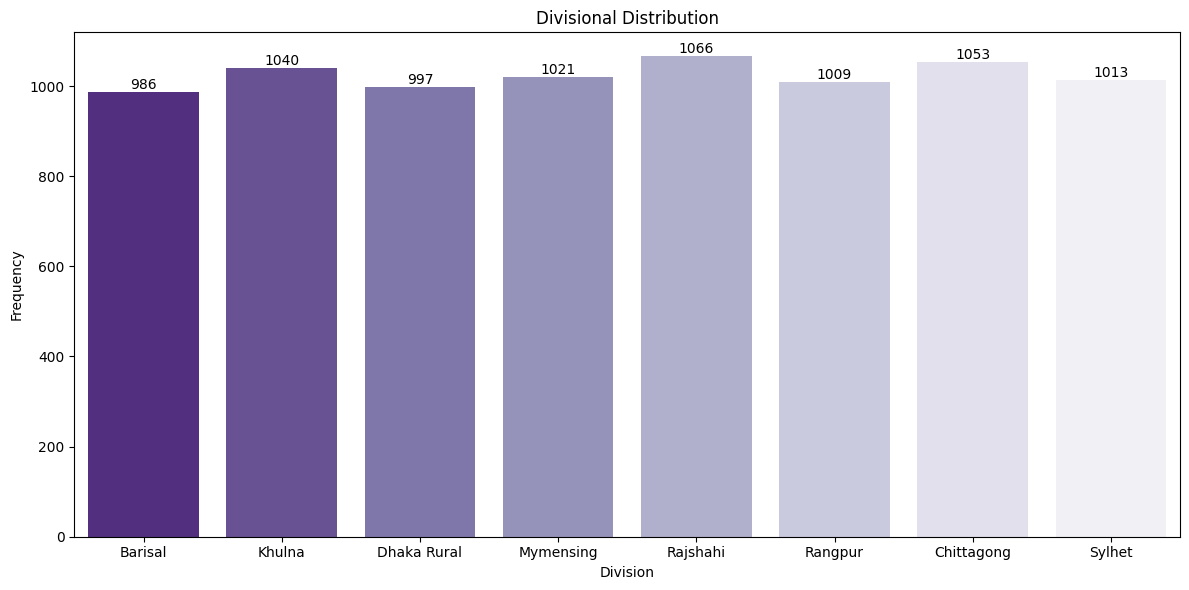

In [ ]:
# Create a dictionary for division mapping
division_mapping = {
    1: 'Barisal',
    2: 'Chittagong',
    3: 'Dhaka Rural',
    4: 'Khulna',
    5: 'Mymensing',
    6: 'Rajshahi',
    7: 'Rangpur',
    8: 'Sylhet'
}

# Assuming 'division_code' is the column in the dataset representing division
df_ncd['division'] = df_ncd['division'].map(division_mapping)

# Function to annotate bars with counts
def annotate_barplot(ax):
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black')

# Plotting the bar chart for division distribution
plt.figure(figsize=(12, 6))

# Division distribution
ax = sns.countplot(x='division', data=df_ncd, palette='Purples_r')
plt.title('Divisional Distribution')
plt.xlabel('Division')
plt.ylabel('Frequency')
annotate_barplot(ax)

# Adjust layout for better presentation
plt.tight_layout()
plt.show()


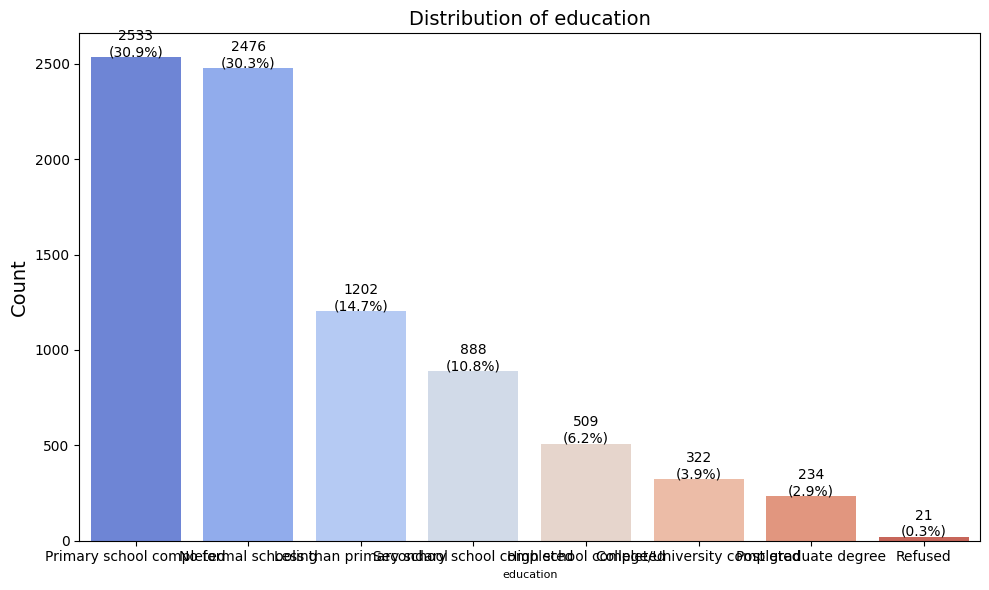

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'df_ncd' is your DataFrame and 'oil-used' is the column for oil used most often
# First, map the values to their corresponding categories
edu_mapping = {
    1: 'No formal schooling',
    2: 'Less than primary school',
    3: 'Primary school completed',
    4: 'Secondary school completed',
    5: 'High school completed',
    6: 'College/University completed',
    7: 'Post graduate degree',
    88: 'Refused',

}

# Map the 'oil-used' column to oil categories
df_ncd['education'] = df_ncd['education'].map(edu_mapping)

# Count the occurrences of each category
oil_counts = df_ncd['education'].value_counts()

# Plot the distribution using a bar plot
plt.figure(figsize=(10, 6))
sns.barplot(x=oil_counts.index, y=oil_counts.values, palette='coolwarm')
plt.title('Distribution of education', fontsize=14)
plt.xlabel('education', fontsize=8)
plt.ylabel('Count', fontsize=14)

# Add the count and percentage on top of each bar
total = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()


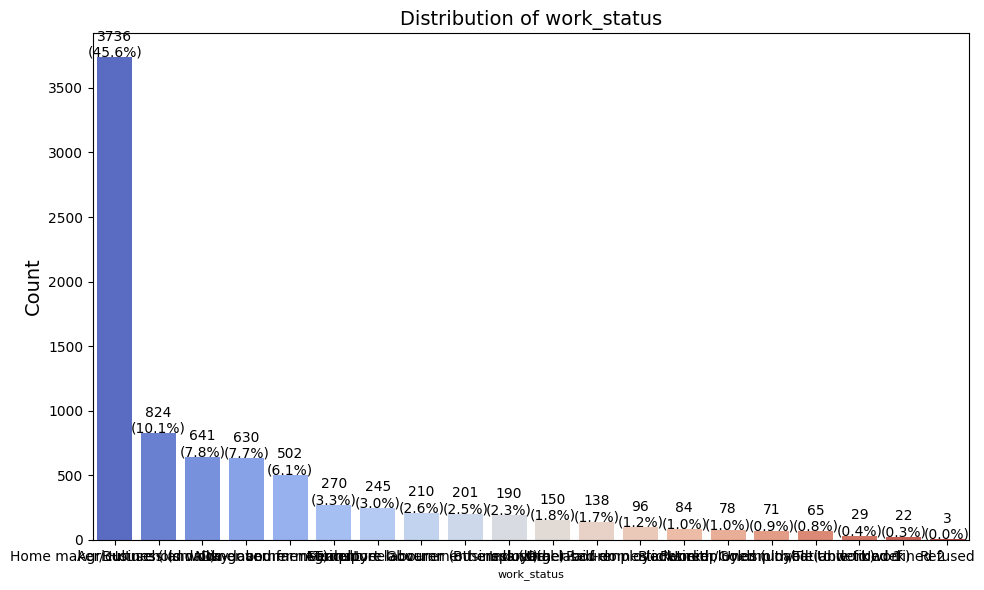

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'df_ncd' is your DataFrame and 'oil-used' is the column for oil used most often
# First, map the values to their corresponding categories
work_mapping = {
    1: 'Government employee',
    2: 'Non-government employee',
    3: 'Business (small)',
    4: 'Business (large)',
    5: 'Agriculture (land owner and farmer)',
    6: 'Agriculture labourer (others land)',
    7: 'Industrial labourer',
    8: 'Day labourer',
    9: 'Transport labourer',
    10: 'Other self-employed',
    11: 'Student',
    12: 'Home maker/ Household work',
    13: 'Retired',
    14: 'Unemployed (able to work)',
    15: 'Unemployed (unable to work)',
    16: 'Paid domestic worker',
    17: 'Blacksmith/Goldsmith/Tati',
    18: 'Undefined 1',
    19: 'Undefined 2',
    88: 'Refused',

}

# Map the 'oil-used' column to oil categories
df_ncd['work_status'] = df_ncd['work_status'].map(work_mapping)

# Count the occurrences of each category
oil_counts = df_ncd['work_status'].value_counts()

# Plot the distribution using a bar plot
plt.figure(figsize=(10, 6))
sns.barplot(x=oil_counts.index, y=oil_counts.values, palette='coolwarm')
plt.title('Distribution of work_status', fontsize=14)
plt.xlabel('work_status', fontsize=8)
plt.ylabel('Count', fontsize=14)

# Add the count and percentage on top of each bar
total = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()


In [ ]:
df_ncd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8185 entries, 0 to 8184
Data columns (total 31 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   education                       8185 non-null   object  
 1   division                        8185 non-null   object  
 2   urbanrural                      8185 non-null   object  
 3   sex                             8185 non-null   object  
 4   age                             8185 non-null   int64   
 5   yrs of education                8185 non-null   int64   
 6   marital_status                  8185 non-null   int64   
 7   work_status                     8185 non-null   object  
 8   current smoking                 8185 non-null   int64   
 9   current daily smoking           8185 non-null   float64 
 10  age started smoking             8185 non-null   float64 
 11  past smoking                    8185 non-null   float64 
 12  past daily smoking  

In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Define the features and safe ranges
features = ['heart rate', 'cholesterol', 'hdl', 'ldl', 'fasting blood glucose', 'triglycerides', 'age', 'height', 'weight',
            'told had high BP', 'told had high gluc', 'current daily smoking', 'past daily smoking', 'past smoking',
            'advised to not smoke']

# Safe ranges for continuous features
safe_ranges = {
    'heart rate': (60, 80),
    'fasting blood glucose': (70, 99),
    'cholesterol': (0, 200),
    'triglycerides': (50, 150),
    'hdl': (45, 100),
    'ldl': (0, 100)
}

# Assign risk levels based on how far values are from safe ranges
def calculate_risk(row):
    risk = 0
    for feature, (low, high) in safe_ranges.items():
        if low <= row[feature] <= high:
            risk += 0  # Low risk, within range
        elif row[feature] < low or row[feature] > high:
            risk += 1  # Increment risk for out-of-range values
    return risk

# Apply risk calculation to the dataset
df_ncd['risk_score'] = df_ncd.apply(calculate_risk, axis=1)

# Binary feature adjustments: Map binary values to reflect risk directly
binary_features = ['told had high BP', 'told had high gluc', 'current daily smoking', 'past daily smoking', 'past smoking',
            'advised to not smoke']

# Map binary values: 1 for high risk, -1 for protective (if applicable), 0 for neutral
df_ncd[binary_features] = df_ncd[binary_features].replace({2: -1, 1: 1, 0: 0})

# Combine risk scores with binary features for clustering
selected_features = list(safe_ranges.keys()) + binary_features + ['risk_score']

# Scale features for clustering
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_ncd[selected_features])

# Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42)
df_ncd['Risk of respiratory'] = kmeans.fit_predict(df_scaled)

# Map the clusters to risk categories
# Use the average risk score for each cluster to determine 'Low', 'Medium', 'High'
cluster_centers = kmeans.cluster_centers_
cluster_risk_scores = cluster_centers[:, selected_features.index('risk_score')]
risk_mapping = dict(zip(np.argsort(cluster_risk_scores), ['Low', 'Medium', 'High']))
df_ncd['Risk of respiratory'] = df_ncd['Risk of respiratory'].map(risk_mapping)

# Output the results
print("Clustering complete. Here is the distribution of risk categories:")
print(df_ncd['Risk of respiratory'].value_counts())
print("First few rows with risk categories:")
print(df_ncd[['Risk of respiratory'] + selected_features].head())

Clustering complete. Here is the distribution of risk categories:
Risk of respiratory
Low       4073
Medium    3706
High       406
Name: count, dtype: int64
First few rows with risk categories:
  Risk of respiratory  heart rate  fasting blood glucose  cholesterol  \
0              Medium      61.000                 97.000      179.000   
1              Medium      80.000                 99.583      169.257   
2              Medium      91.000                100.000      168.000   
3                 Low      95.000                 90.000      134.000   
4              Medium      82.000                 99.000      231.000   

   triglycerides    hdl     ldl  told had high BP  told had high gluc  \
0        105.000 37.000 121.000            -1.000               0.000   
1        146.602 38.165 101.790            -1.000               1.000   
2        140.000 29.000 111.000            -1.000               0.000   
3         68.000 43.000  77.400            -1.000               0.000   
4 

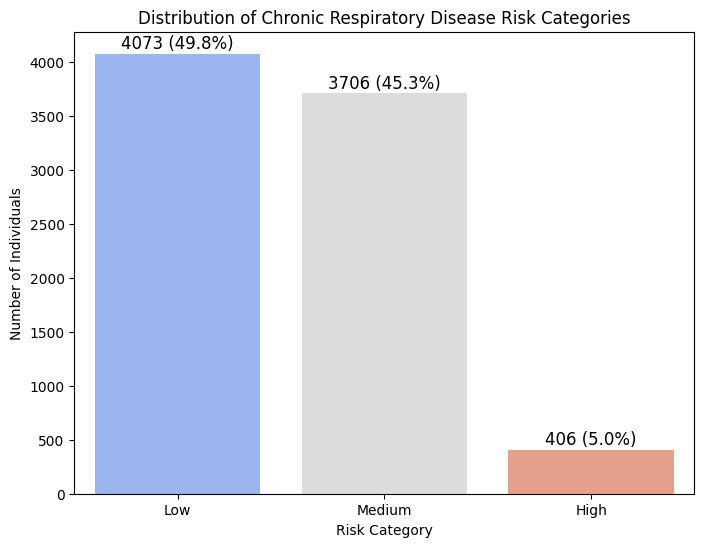

In [ ]:
# Import necessary libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Count the occurrences of each risk category and calculate percentages
risk_counts = df_ncd['Risk of respiratory'].value_counts()
risk_percentages = (risk_counts / risk_counts.sum()) * 100

# Set up the plot
plt.figure(figsize=(8, 6))
sns.barplot(x=risk_counts.index, y=risk_counts.values, palette="coolwarm")

# Add titles and labels
plt.title("Distribution of Chronic Respiratory Disease Risk Categories")
plt.xlabel("Risk Category")
plt.ylabel("Number of Individuals")

# Add percentage and count labels on top of each bar
for i, (count, pct) in enumerate(zip(risk_counts.values, risk_percentages.values)):
    plt.text(i, count + 10, f'{count} ({pct:.1f}%)', ha='center', va='bottom', fontsize=12)

plt.xticks(rotation=0)
plt.show()



In [ ]:
# Separate data into High, Medium, and Low risk categories
high_risk = df_ncd[df_ncd['Risk of respiratory'] == 'High']
medium_risk = df_ncd[df_ncd['Risk of respiratory'] == 'Medium']
low_risk = df_ncd[df_ncd['Risk of respiratory'] == 'Low']

# Calculate descriptive statistics for each risk category
high_risk_stats = high_risk[features].describe()
medium_risk_stats = medium_risk[features].describe()
low_risk_stats = low_risk[features].describe()

# Display the statistics for each risk category
print("High Risk Category Statistics:")
print(high_risk_stats)

print("\nMedium Risk Category Statistics:")
print(medium_risk_stats)

print("\nLow Risk Category Statistics:")
print(low_risk_stats)


High Risk Category Statistics:
       heart rate  cholesterol     hdl     ldl  fasting blood glucose  \
count     406.000      406.000 406.000 406.000                406.000   
mean       82.208      199.670  35.845  99.230                208.200   
std        11.807       47.779   7.871  48.383                 76.614   
min        45.000       96.000  21.000 -67.600                 84.000   
25%        74.250      169.250  31.000  71.600                150.750   
50%        82.000      196.500  35.000 103.000                197.000   
75%        90.000      221.000  39.000 126.300                246.750   
max       118.000      650.000  66.000 367.800                535.000   

       triglycerides     age  height  weight  told had high BP  \
count        406.000 406.000 406.000 406.000           406.000   
mean         322.975  46.039 157.419  62.999            -0.074   
std          222.032  10.449   8.832  11.504             0.937   
min           65.000  21.000 116.600  36.000   

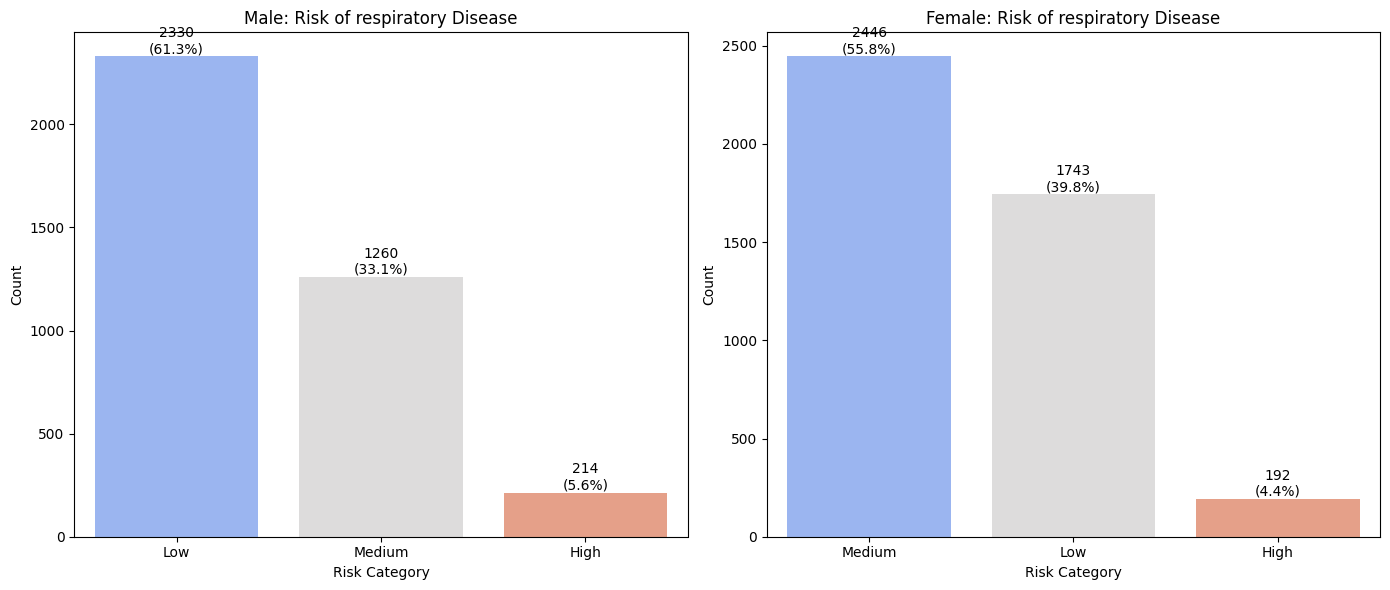

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df_ncd has 'sex' and 'Risk of respiratory' columns
# Separate data for male and female
male_data = df_ncd[df_ncd['sex'] == 'Male']
female_data = df_ncd[df_ncd['sex'] == 'Female']

# Calculate counts and percentages for each category
male_counts = male_data['Risk of respiratory'].value_counts()
male_percentages = male_data['Risk of respiratory'].value_counts(normalize=True) * 100

female_counts = female_data['Risk of respiratory'].value_counts()
female_percentages = female_data['Risk of respiratory'].value_counts(normalize=True) * 100

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Male Risk of respiratory (Counts and Percentages)
sns.barplot(x=male_counts.index, y=male_counts.values, ax=axes[0], palette='coolwarm')
axes[0].set_title('Male: Risk of respiratory Disease')
axes[0].set_xlabel('Risk Category')
axes[0].set_ylabel('Count')

# Adding count and percentage labels for males
for i, count in enumerate(male_counts):
    axes[0].text(i, count + 1, f'{count}\n({male_percentages[i]:.1f}%)',
                 ha='center', va='bottom', color='black', fontsize=10)

# Female Risk of respiratory (Counts and Percentages)
sns.barplot(x=female_counts.index, y=female_counts.values, ax=axes[1], palette='coolwarm')
axes[1].set_title('Female: Risk of respiratory Disease')
axes[1].set_xlabel('Risk Category')
axes[1].set_ylabel('Count')

# Adding count and percentage labels for females
for i, count in enumerate(female_counts):
    axes[1].text(i, count + 1, f'{count}\n({female_percentages[i]:.1f}%)',
                 ha='center', va='bottom', color='black', fontsize=10)

plt.tight_layout()
plt.show()


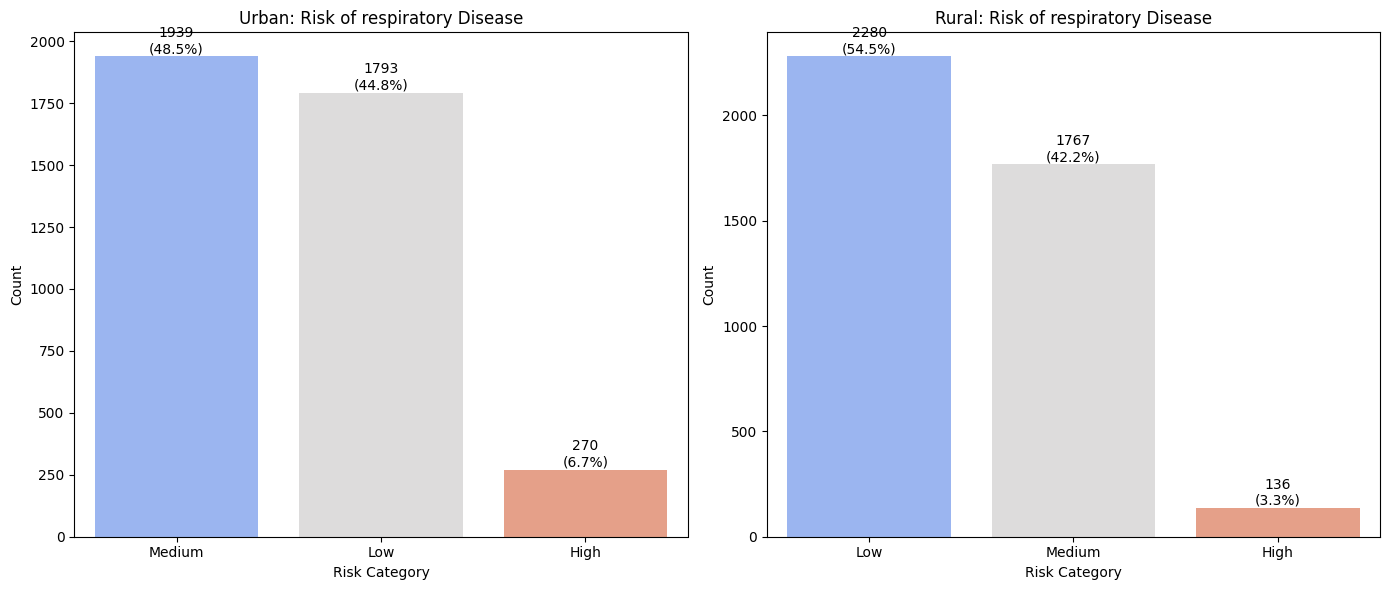

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Separate data for urban and rural categories
urban_data = df_ncd[df_ncd['urbanrural'] == 'Urban']  # or df_ncd['urbanrural'] == 1
rural_data = df_ncd[df_ncd['urbanrural'] == 'Rural']  # or df_ncd['urbanrural'] == 2

# Calculate counts and percentages for each category
urban_counts = urban_data['Risk of respiratory'].value_counts()
urban_percentages = urban_data['Risk of respiratory'].value_counts(normalize=True) * 100

rural_counts = rural_data['Risk of respiratory'].value_counts()
rural_percentages = rural_data['Risk of respiratory'].value_counts(normalize=True) * 100

# Plotting counts and percentages for each risk category in Urban and Rural
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Urban Risk of respiratory (Counts and Percentages)
sns.barplot(x=urban_counts.index, y=urban_counts.values, ax=axes[0], palette='coolwarm')
axes[0].set_title('Urban: Risk of respiratory Disease')
axes[0].set_xlabel('Risk Category')
axes[0].set_ylabel('Count')

# Adding count and percentage labels for Urban data
for i, count in enumerate(urban_counts):
    percentage = urban_percentages[i]
    axes[0].text(i, count + 1, f'{count}\n({percentage:.1f}%)',
                 ha='center', va='bottom', color='black', fontsize=10)

# Rural Risk of respiratory (Counts and Percentages)
sns.barplot(x=rural_counts.index, y=rural_counts.values, ax=axes[1], palette='coolwarm')
axes[1].set_title('Rural: Risk of respiratory Disease')
axes[1].set_xlabel('Risk Category')
axes[1].set_ylabel('Count')

# Adding count and percentage labels for Rural data
for i, count in enumerate(rural_counts):
    percentage = rural_percentages[i]
    axes[1].text(i, count + 1, f'{count}\n({percentage:.1f}%)',
                 ha='center', va='bottom', color='black', fontsize=10)

plt.tight_layout()
plt.show()


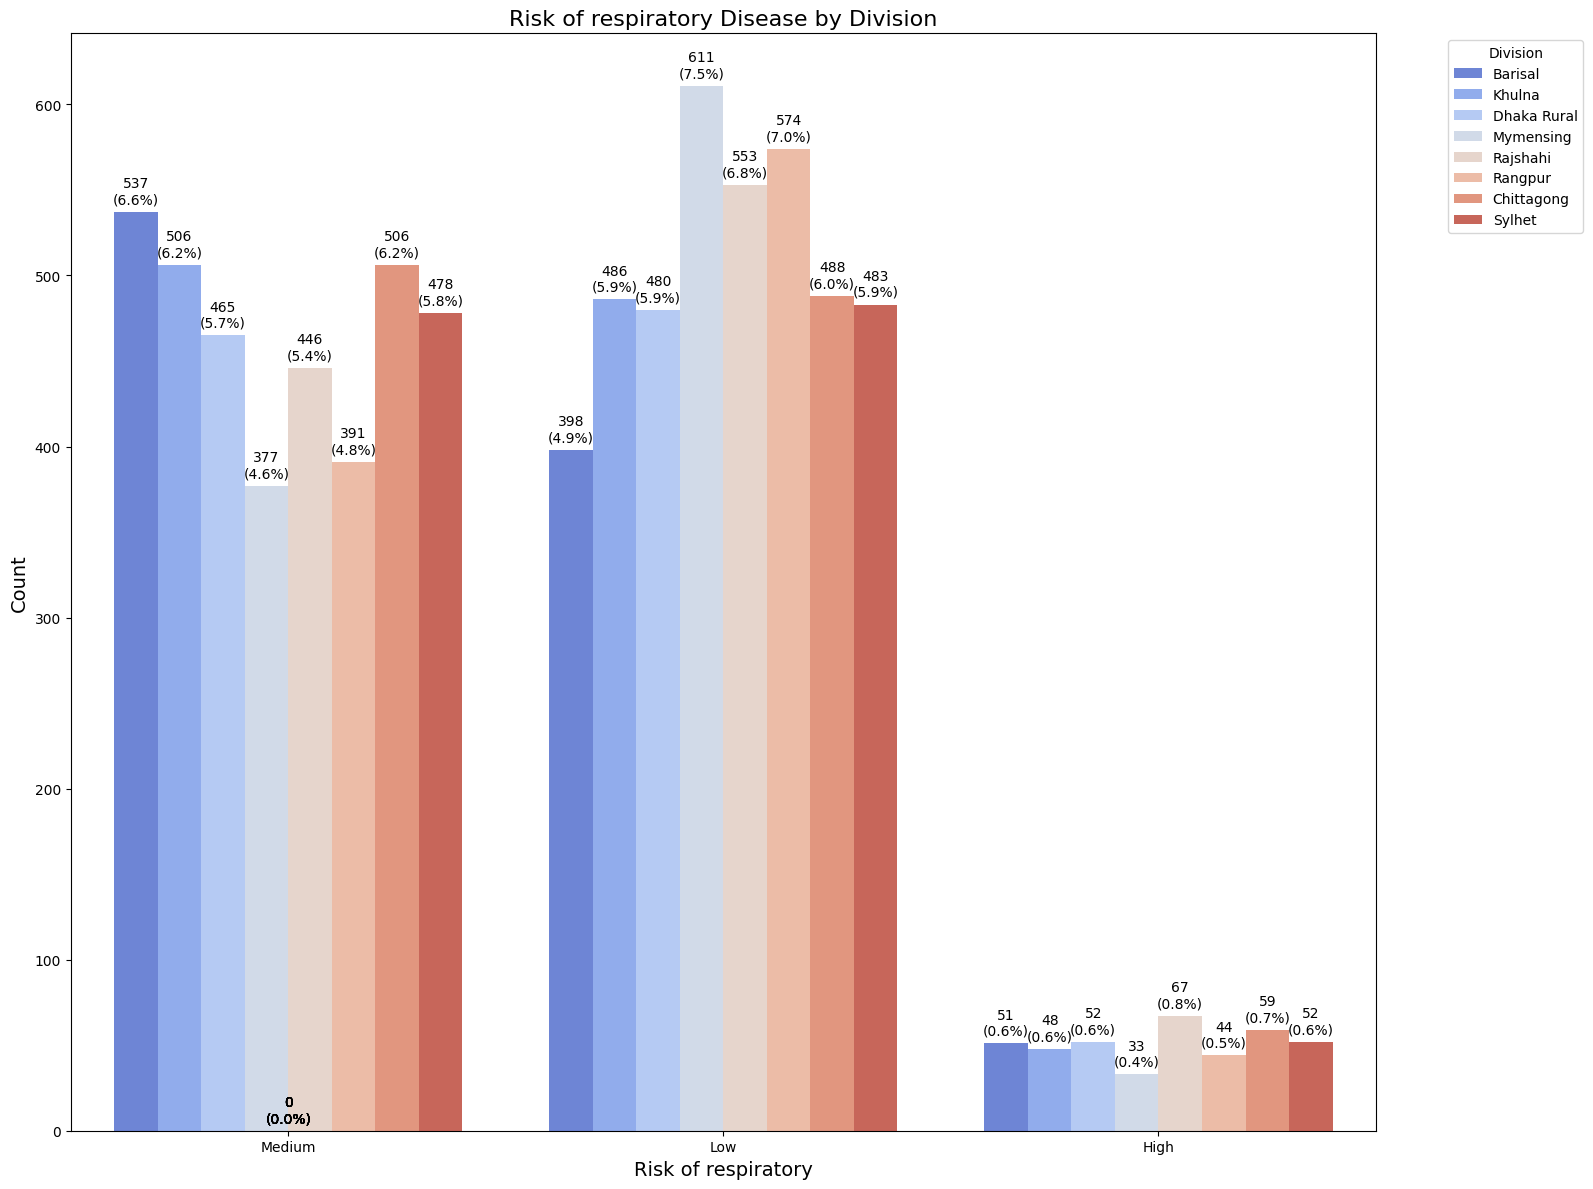

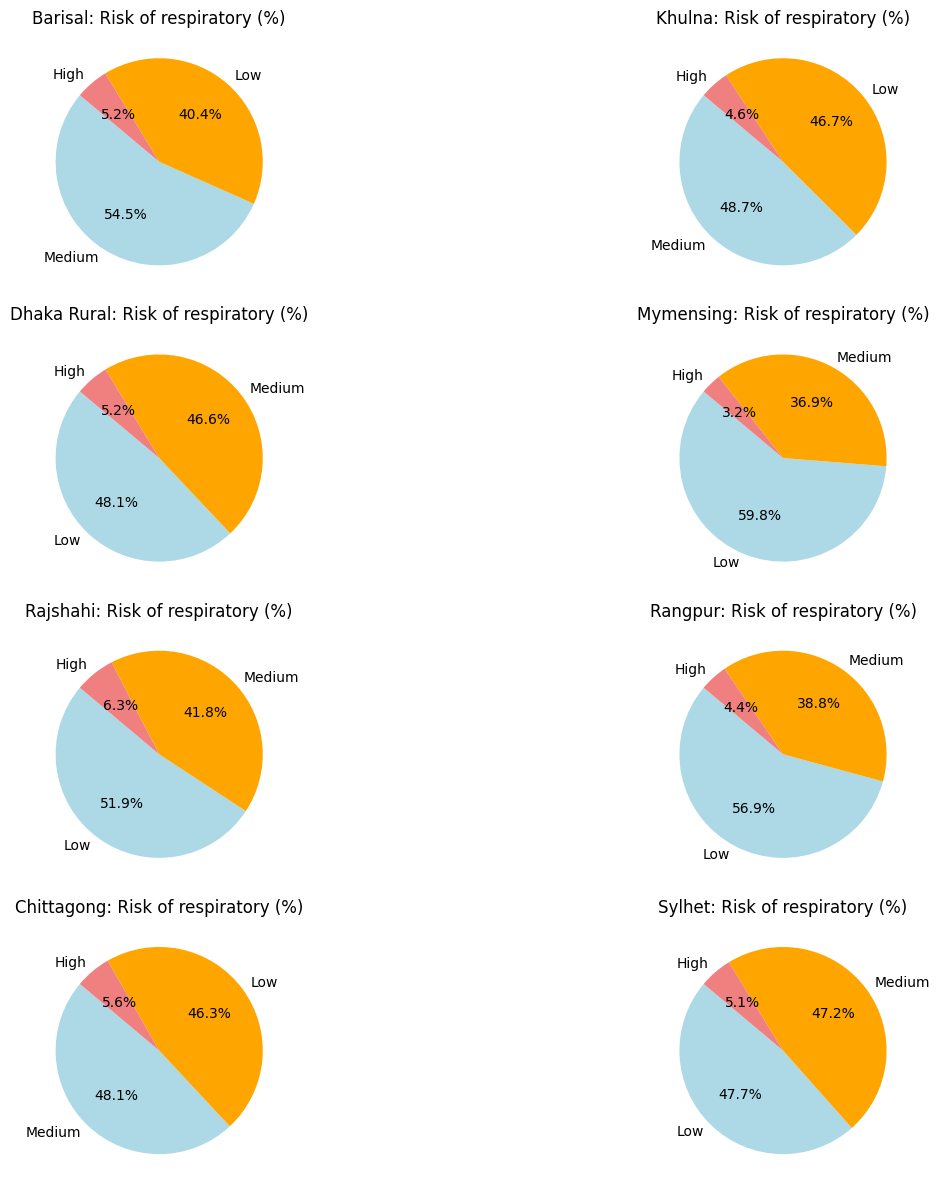

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Overall count plot with both counts and percentages for each risk level across divisions
plt.figure(figsize=(16, 12))
sns.countplot(x='Risk of respiratory', hue='division', data=df_ncd, palette='coolwarm')
plt.title('Risk of respiratory Disease by Division', fontsize=16)
plt.xlabel('Risk of respiratory', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='Division', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add count and percentage annotations on top of each bar
total_counts = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total_counts
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()

# Pie charts for each division
divisions = df_ncd['division'].unique()
num_divisions = len(divisions)
plt.figure(figsize=(16, 12))

for idx, division in enumerate(divisions, 1):
    division_data = df_ncd[df_ncd['division'] == division]
    division_counts = division_data['Risk of respiratory'].value_counts()

    plt.subplot((num_divisions + 1) // 2, 2, idx)  # Arrange pie charts in a grid
    plt.pie(division_counts, labels=division_counts.index, autopct='%1.1f%%',
            colors=['lightblue', 'orange', 'lightcoral'], startangle=140)
    plt.title(f'{division}: Risk of respiratory (%)')

plt.tight_layout()
plt.show()


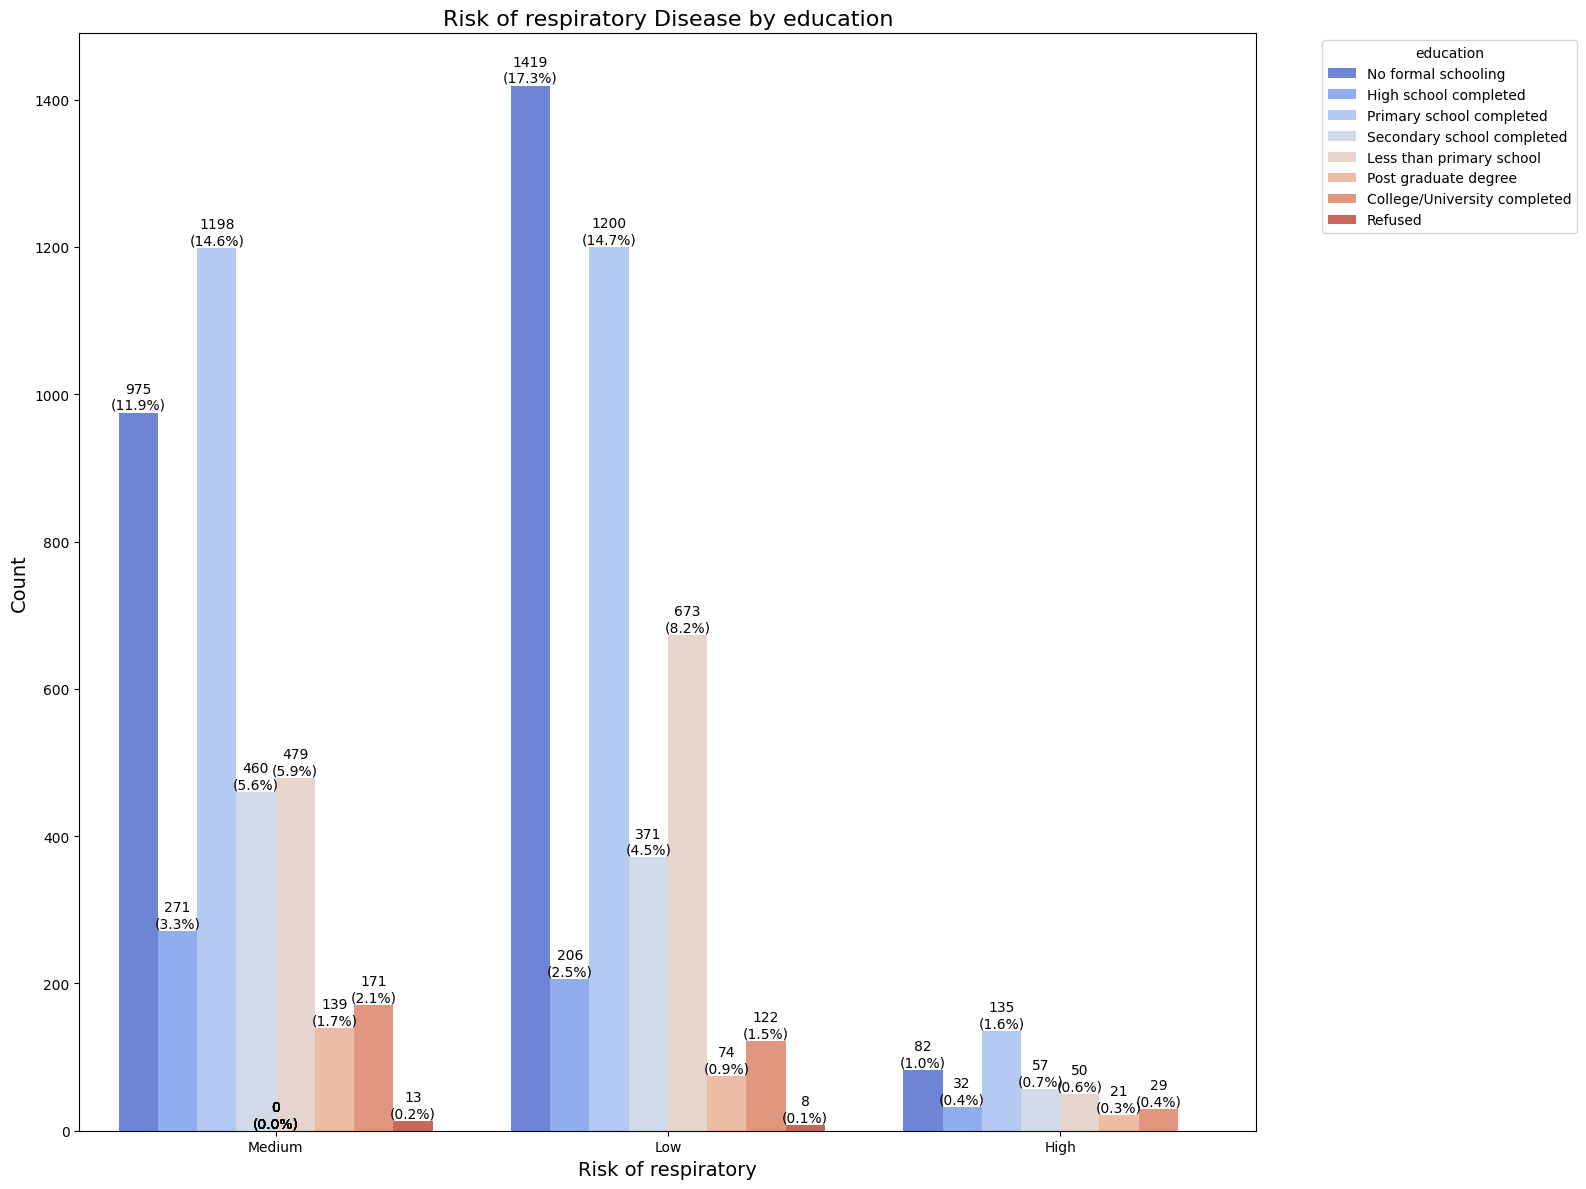

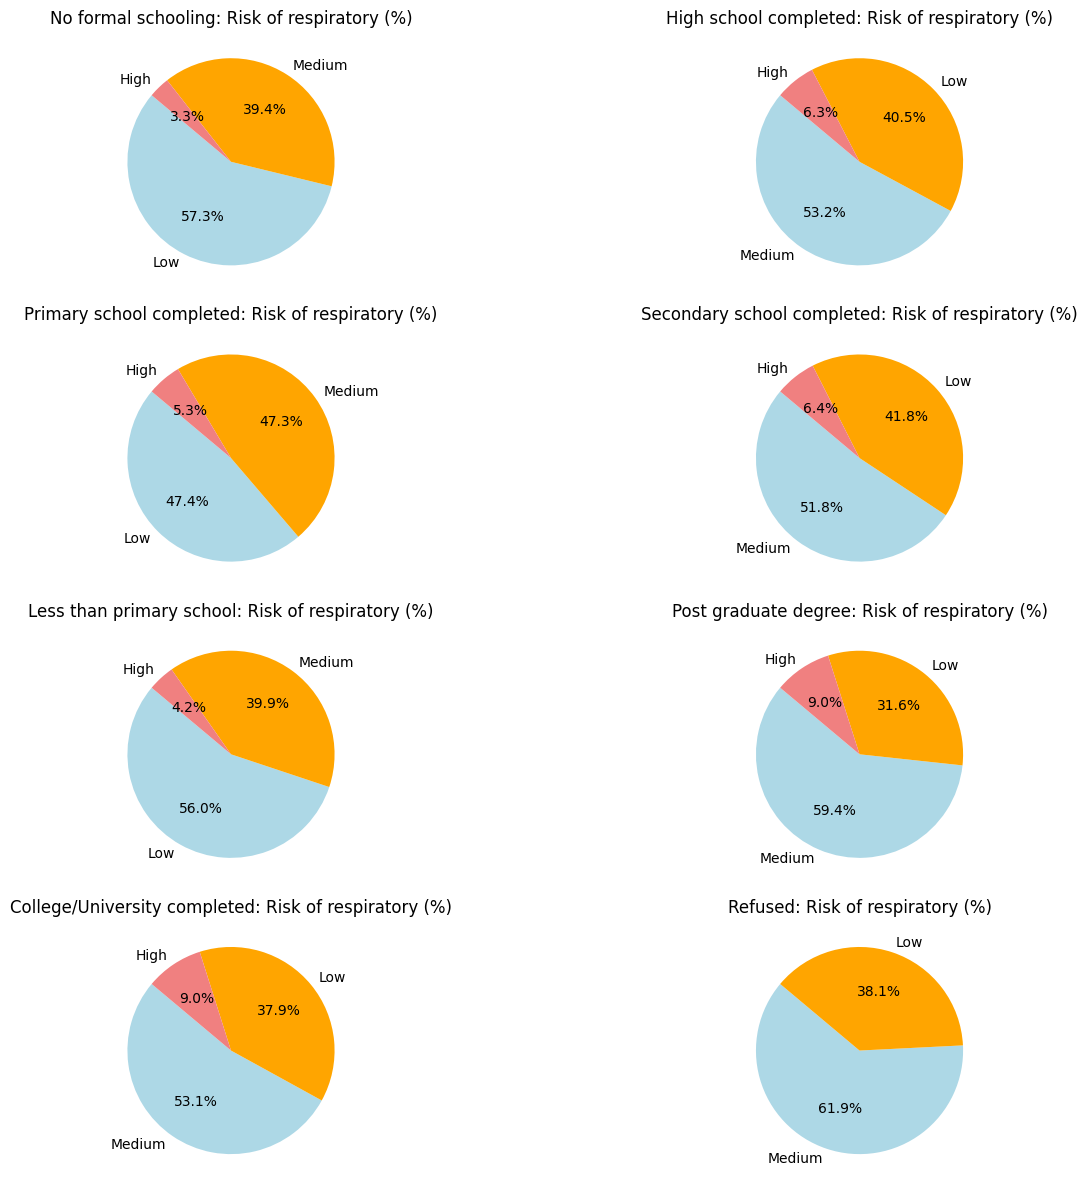

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Overall count plot with both counts and percentages for each risk level across educations
plt.figure(figsize=(16, 12))
sns.countplot(x='Risk of respiratory', hue='education', data=df_ncd, palette='coolwarm')
plt.title('Risk of respiratory Disease by education', fontsize=16)
plt.xlabel('Risk of respiratory', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='education', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add count and percentage annotations on top of each bar
total_counts = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total_counts
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()

# Pie charts for each education
educations = df_ncd['education'].unique()
num_educations = len(educations)
plt.figure(figsize=(16, 12))

for idx, education in enumerate(educations, 1):
    education_data = df_ncd[df_ncd['education'] == education]
    education_counts = education_data['Risk of respiratory'].value_counts()

    plt.subplot((num_educations + 1) // 2, 2, idx)  # Arrange pie charts in a grid
    plt.pie(education_counts, labels=education_counts.index, autopct='%1.1f%%',
            colors=['lightblue', 'orange', 'lightcoral'], startangle=140)
    plt.title(f'{education}: Risk of respiratory (%)')

plt.tight_layout()
plt.show()


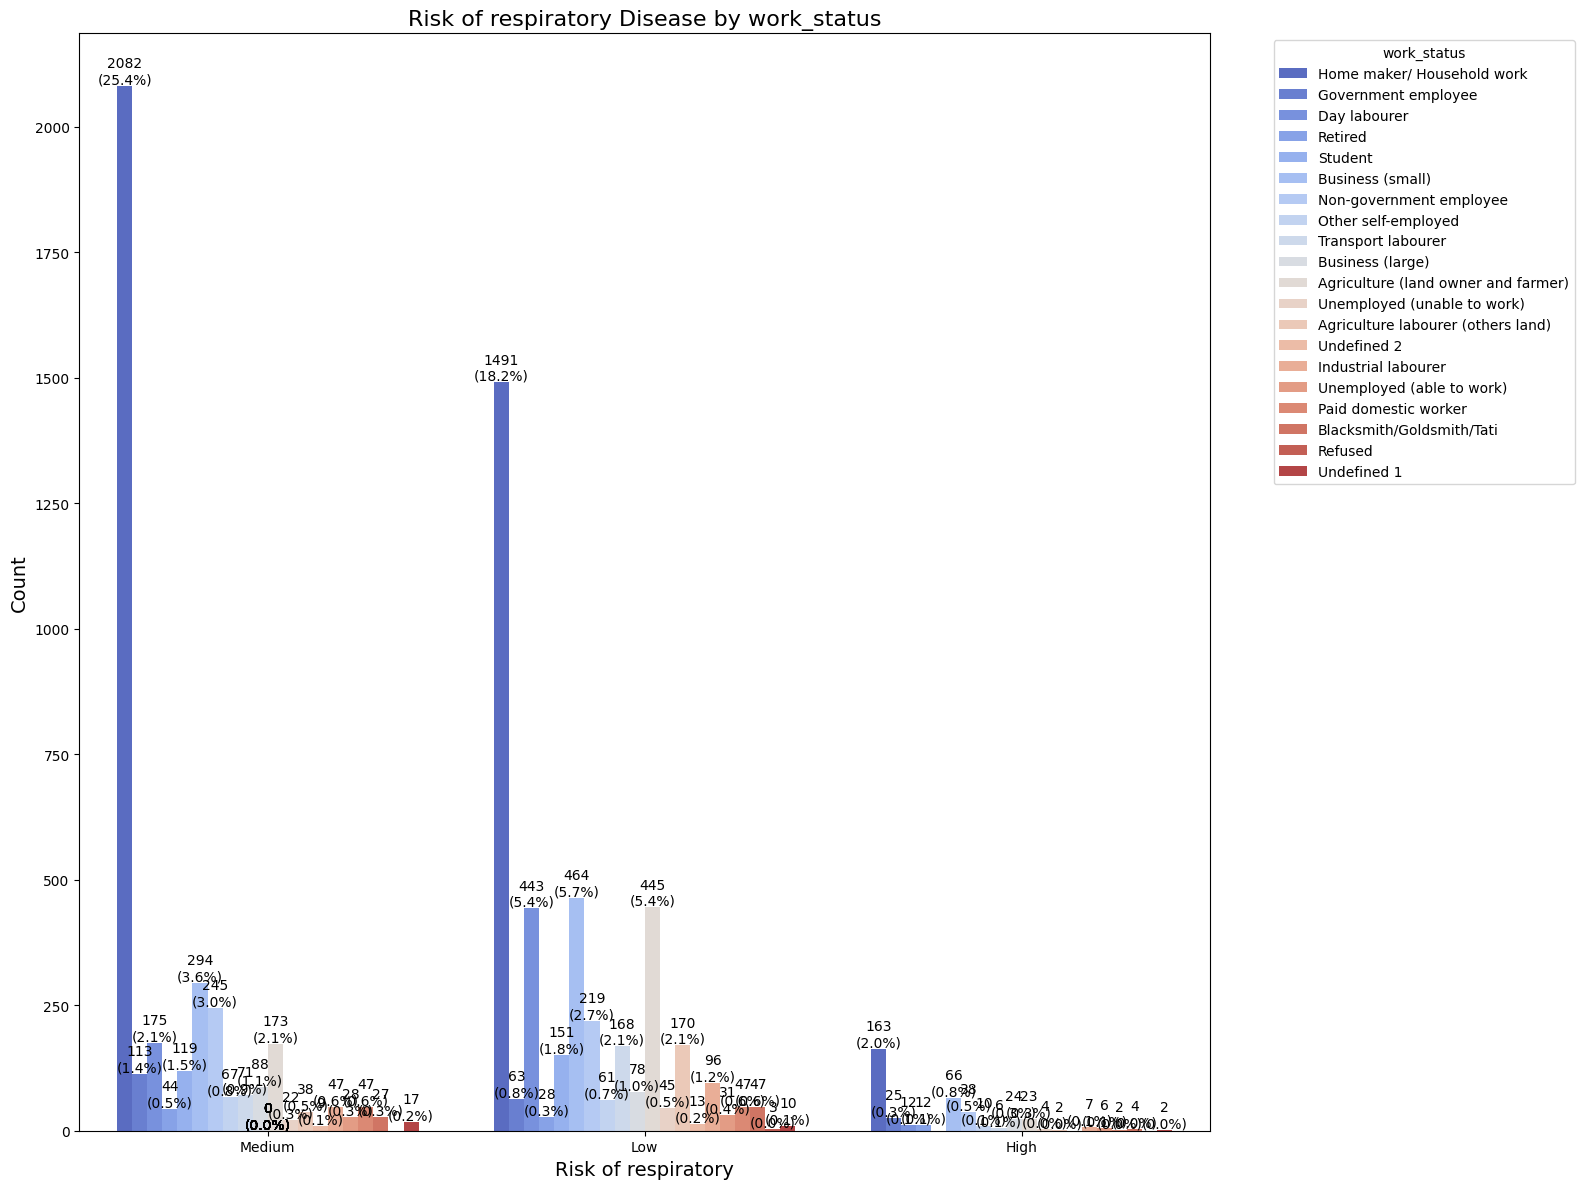

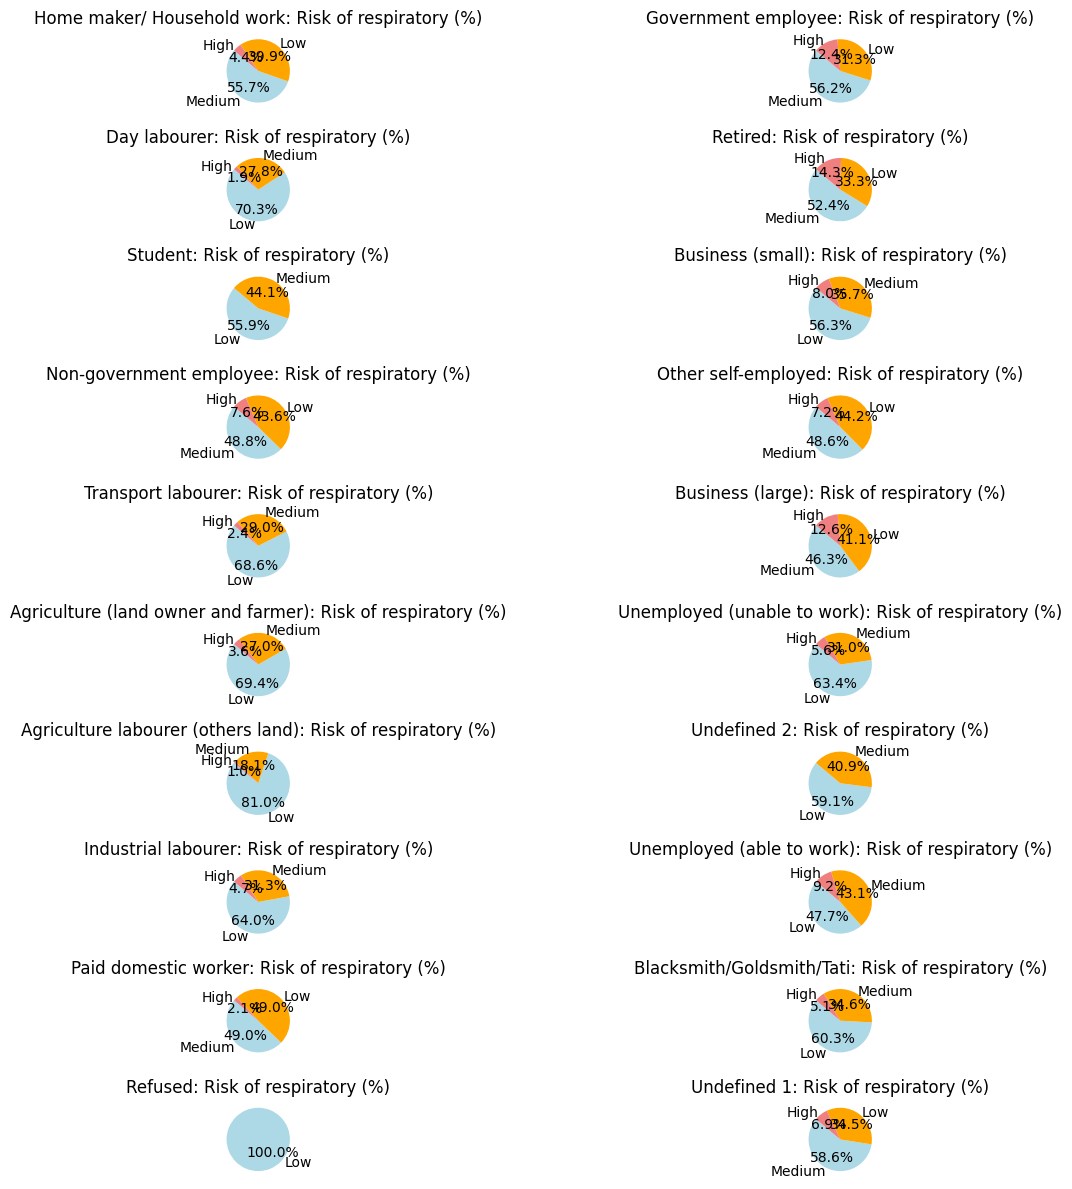

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Overall count plot with both counts and percentages for each risk level across work_statuss
plt.figure(figsize=(16, 12))
sns.countplot(x='Risk of respiratory', hue='work_status', data=df_ncd, palette='coolwarm')
plt.title('Risk of respiratory Disease by work_status', fontsize=16)
plt.xlabel('Risk of respiratory', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='work_status', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add count and percentage annotations on top of each bar
total_counts = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total_counts
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()

# Pie charts for each work_status
work_statuss = df_ncd['work_status'].unique()
num_work_statuss = len(work_statuss)
plt.figure(figsize=(16, 12))

for idx, work_status in enumerate(work_statuss, 1):
    work_status_data = df_ncd[df_ncd['work_status'] == work_status]
    work_status_counts = work_status_data['Risk of respiratory'].value_counts()

    plt.subplot((num_work_statuss + 1) // 2, 2, idx)  # Arrange pie charts in a grid
    plt.pie(work_status_counts, labels=work_status_counts.index, autopct='%1.1f%%',
            colors=['lightblue', 'orange', 'lightcoral'], startangle=140)
    plt.title(f'{work_status}: Risk of respiratory (%)')

plt.tight_layout()
plt.show()


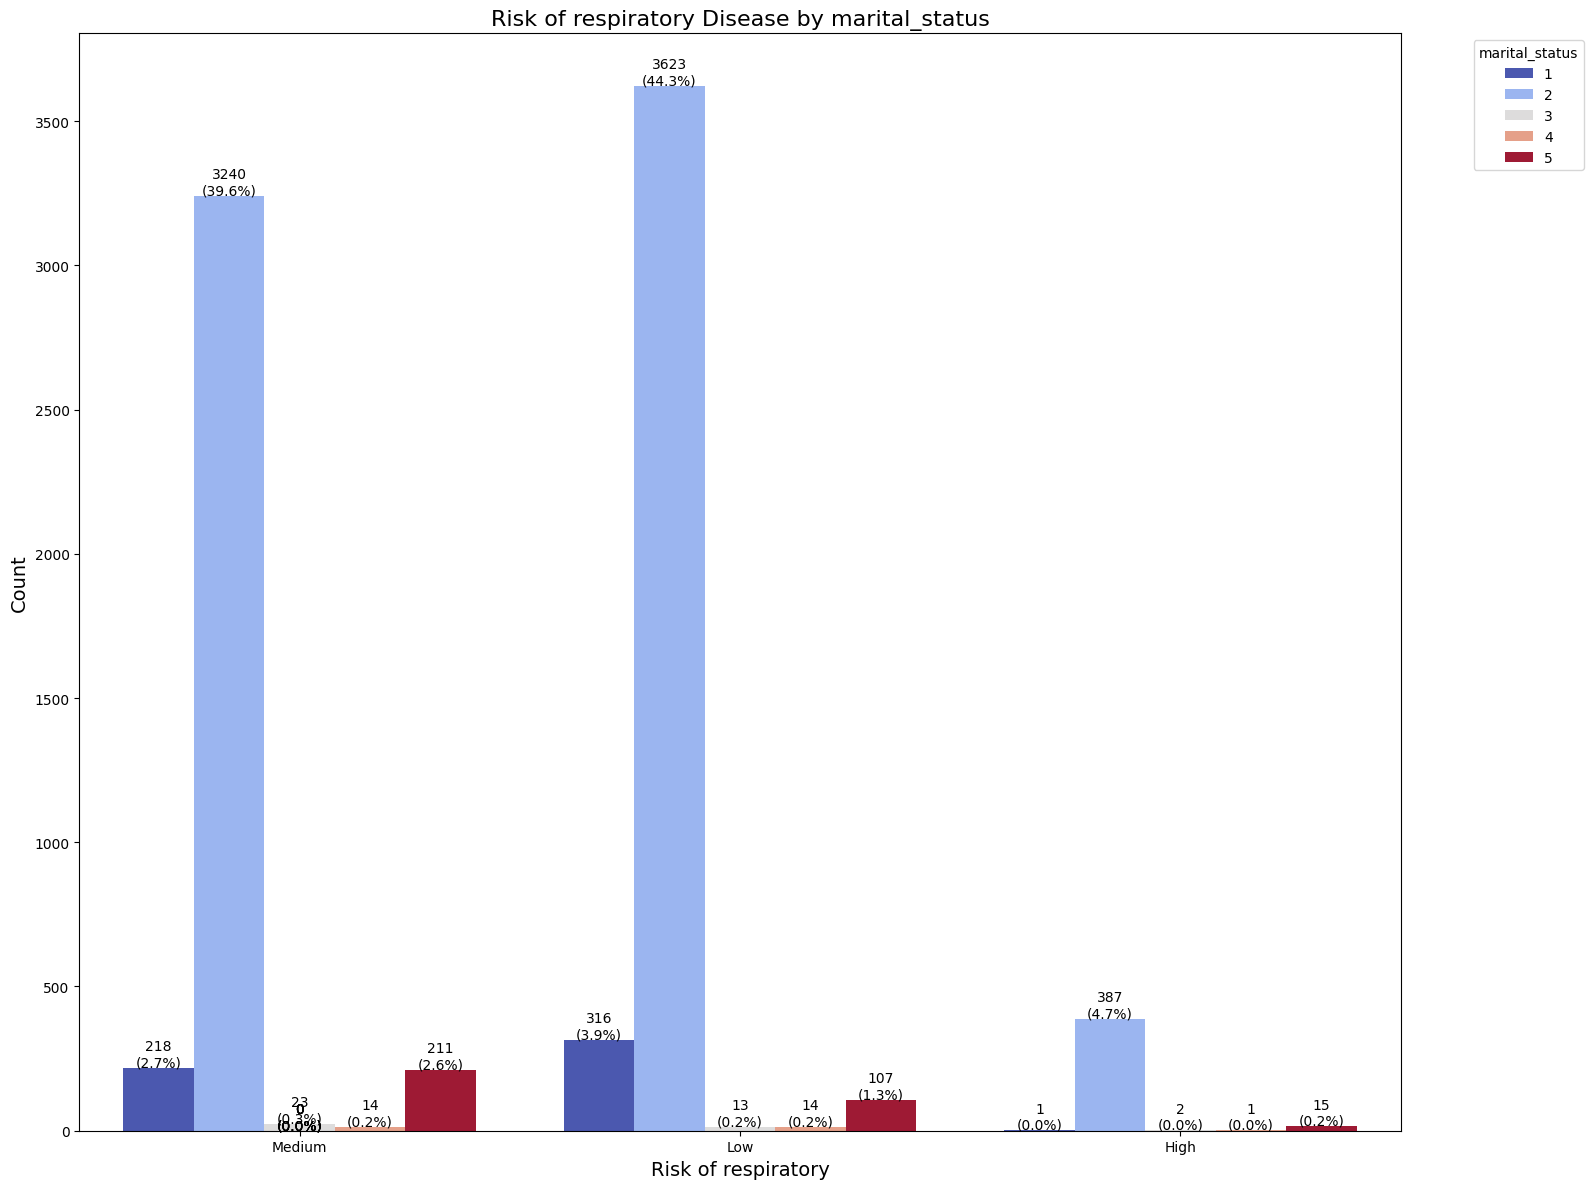

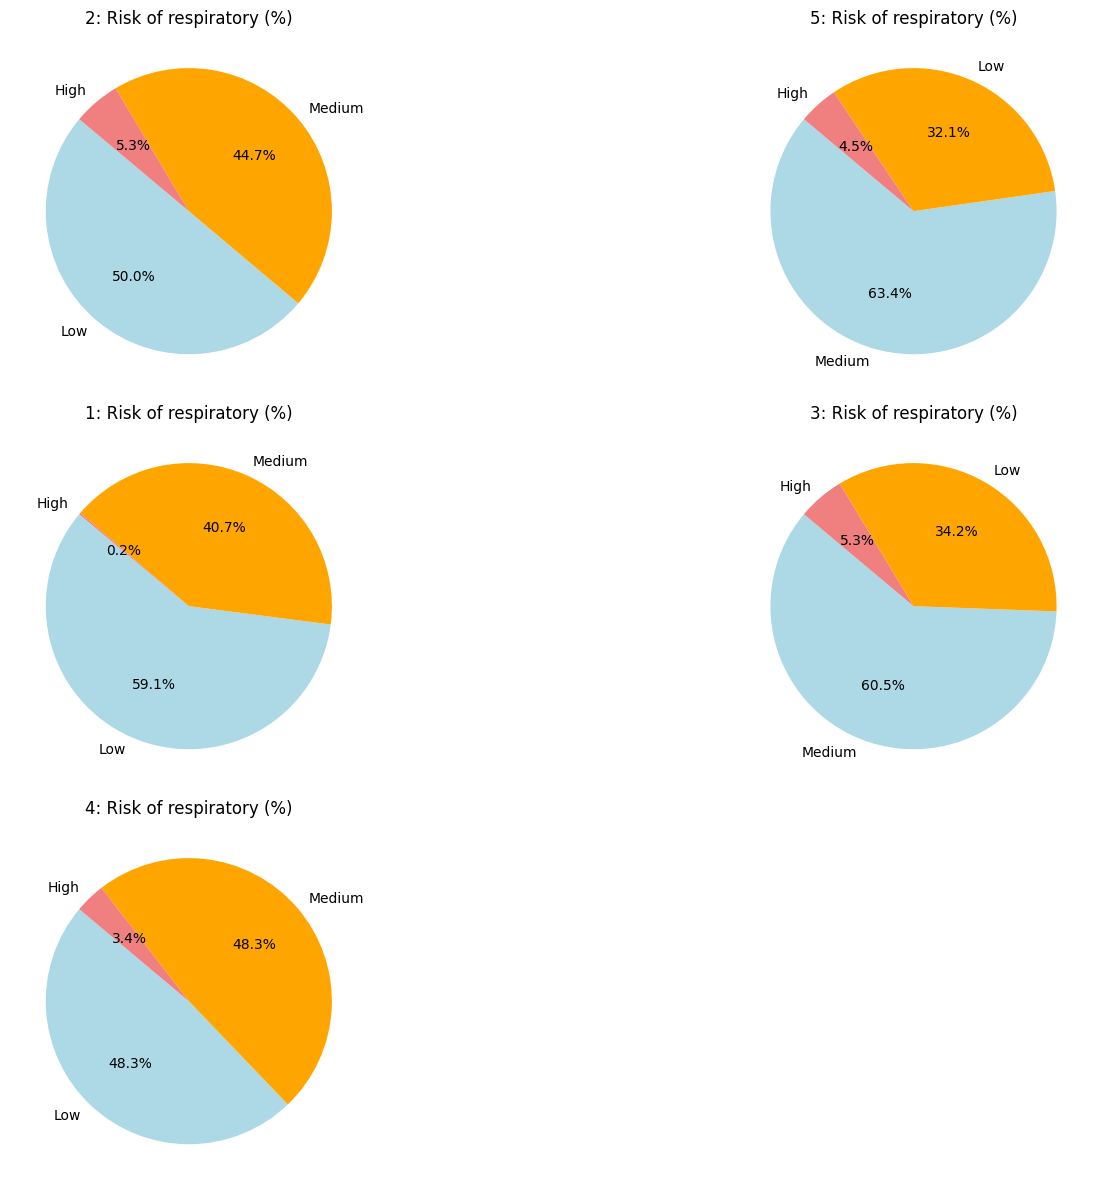

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Overall count plot with both counts and percentages for each risk level across marital_statuss
plt.figure(figsize=(16, 12))
sns.countplot(x='Risk of respiratory', hue='marital_status', data=df_ncd, palette='coolwarm')
plt.title('Risk of respiratory Disease by marital_status', fontsize=16)
plt.xlabel('Risk of respiratory', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='marital_status', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add count and percentage annotations on top of each bar
total_counts = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total_counts
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()

# Pie charts for each marital_status
marital_statuss = df_ncd['marital_status'].unique()
num_marital_statuss = len(marital_statuss)
plt.figure(figsize=(16, 12))

for idx, marital_status in enumerate(marital_statuss, 1):
    marital_status_data = df_ncd[df_ncd['marital_status'] == marital_status]
    marital_status_counts = marital_status_data['Risk of respiratory'].value_counts()

    plt.subplot((num_marital_statuss + 1) // 2, 2, idx)  # Arrange pie charts in a grid
    plt.pie(marital_status_counts, labels=marital_status_counts.index, autopct='%1.1f%%',
            colors=['lightblue', 'orange', 'lightcoral'], startangle=140)
    plt.title(f'{marital_status}: Risk of respiratory (%)')

plt.tight_layout()
plt.show()


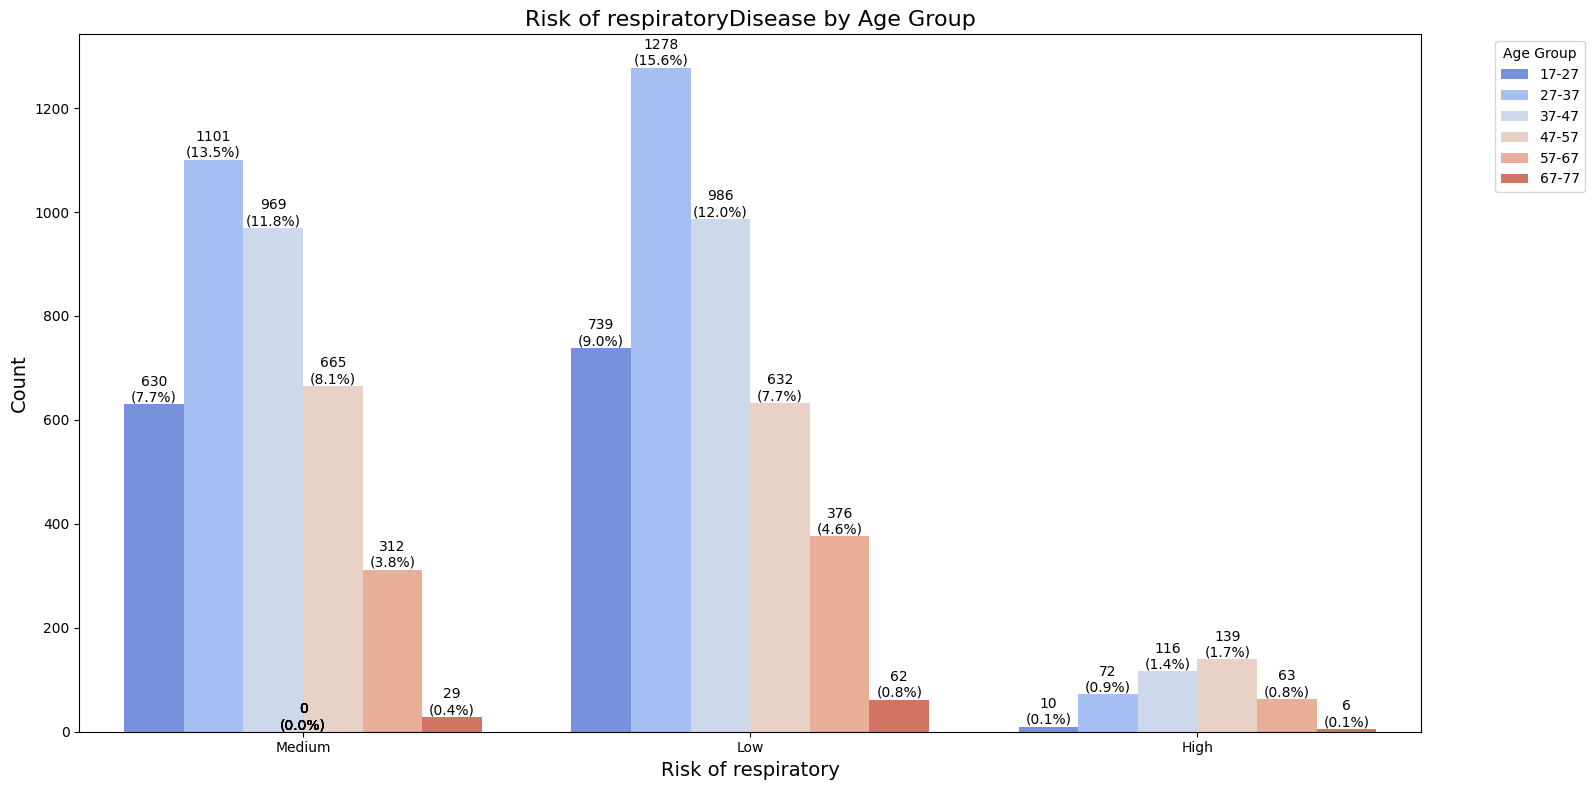

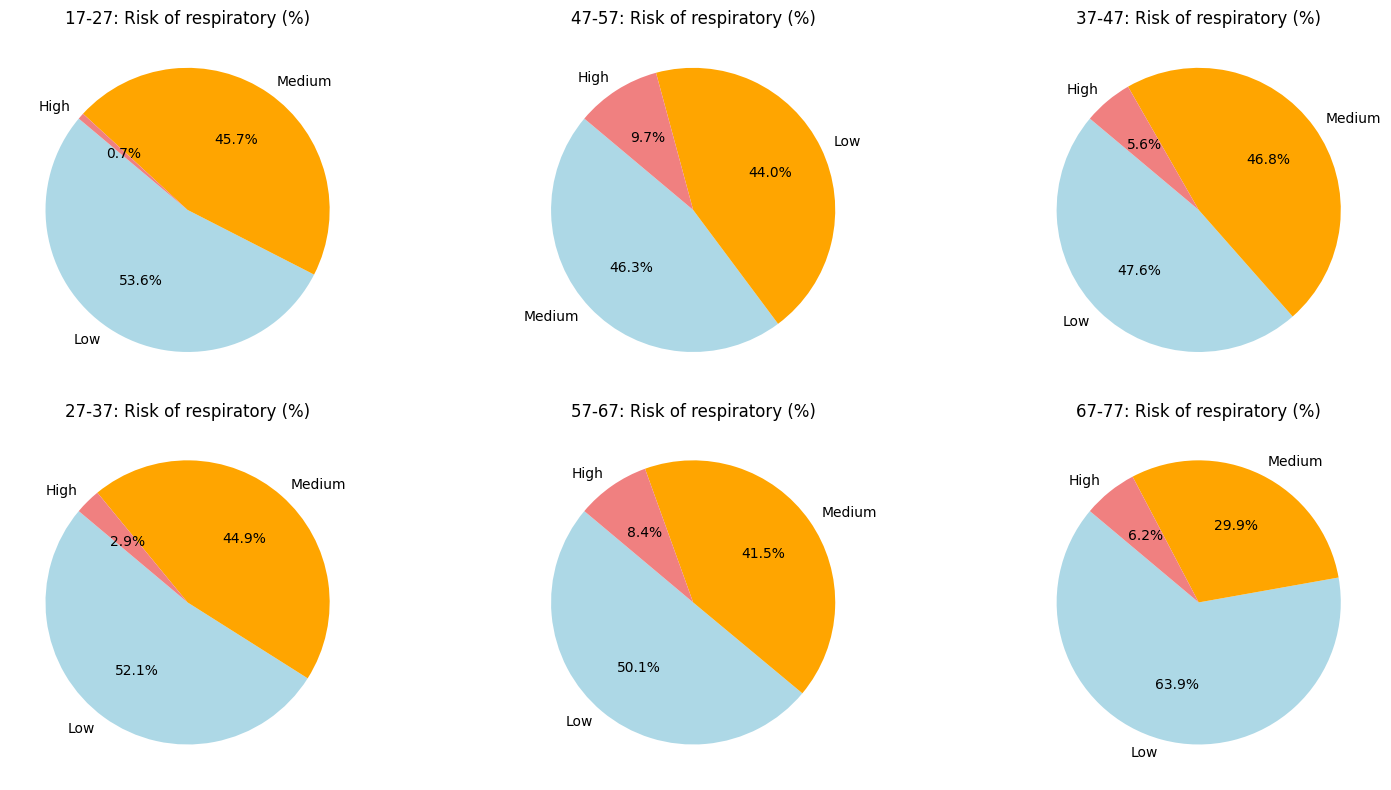

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Step 1: Create age groups
age_bins = [17, 27, 37, 47, 57, 67, 77]  # Age bin boundaries
age_labels = ['17-27', '27-37', '37-47', '47-57', '57-67', '67-77']  # Age group labels

# Add the age group column to the dataset
df_ncd['age_group'] = pd.cut(df_ncd['age'], bins=age_bins, labels=age_labels, right=False)

# Step 2: Overall count plot with counts and percentages
plt.figure(figsize=(16, 8))
sns.countplot(x='Risk of respiratory', hue='age_group', data=df_ncd, palette='coolwarm')
plt.title('Risk of respiratoryDisease by Age Group', fontsize=16)
plt.xlabel('Risk of respiratory', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='Age Group', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add count and percentage annotations
total_counts = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total_counts
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()

# Step 3: Pie charts for each age group
age_groups = df_ncd['age_group'].unique()
num_age_groups = len(age_groups)
plt.figure(figsize=(16, 8))

for idx, age_group in enumerate(age_groups, 1):
    age_group_data = df_ncd[df_ncd['age_group'] == age_group]
    age_group_counts = age_group_data['Risk of respiratory'].value_counts()

    plt.subplot((num_age_groups + 2) // 3, 3, idx)  # Arrange pie charts in a grid
    plt.pie(age_group_counts, labels=age_group_counts.index, autopct='%1.1f%%',
            colors=['lightblue', 'orange', 'lightcoral'], startangle=140)
    plt.title(f'{age_group}: Risk of respiratory (%)')

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.model_selection import train_test_split

# Define X (features) and y (target)
X = df_ncd[features]  # Features from clustering
y = df_ncd['Risk of respiratory']  # Target variable

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report

# Dictionary to store models and their names
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Support Vector Machine': SVC(random_state=42)
}

# Dictionary to hold evaluation results
results = {}

# Train and evaluate each model
for name, model in models.items():
    model.fit(X_train, y_train)  # Train model
    y_pred = model.predict(X_test)  # Make predictions on test set

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')

    # Store results
    results[name] = {
        'Accuracy': accuracy,
        'F1 Score': f1,
        'Precision': precision,
        'Recall': recall
    }
    # Print classification report for each model
    print(f"Classification Report for {name}:\n", classification_report(y_test, y_pred))


Classification Report for Logistic Regression:
               precision    recall  f1-score   support

        High       0.89      0.96      0.92        68
         Low       0.92      0.89      0.91       864
      Medium       0.87      0.90      0.89       705

    accuracy                           0.90      1637
   macro avg       0.89      0.92      0.90      1637
weighted avg       0.90      0.90      0.90      1637

Classification Report for K-Nearest Neighbors:
               precision    recall  f1-score   support

        High       0.85      0.91      0.88        68
         Low       0.90      0.86      0.88       864
      Medium       0.83      0.86      0.85       705

    accuracy                           0.86      1637
   macro avg       0.86      0.88      0.87      1637
weighted avg       0.86      0.86      0.86      1637

Classification Report for Decision Tree:
               precision    recall  f1-score   support

        High       0.83      0.87      0.85  

In [ ]:
import pandas as pd

# Convert results to DataFrame
results_df = pd.DataFrame(results).T  # Transpose for easier viewing
print(results_df)


                        Accuracy  F1 Score  Precision  Recall
Logistic Regression        0.897     0.898      0.898   0.897
K-Nearest Neighbors        0.863     0.863      0.865   0.863
Decision Tree              0.921     0.921      0.922   0.921
Random Forest              0.944     0.944      0.944   0.944
Support Vector Machine     0.870     0.871      0.873   0.870


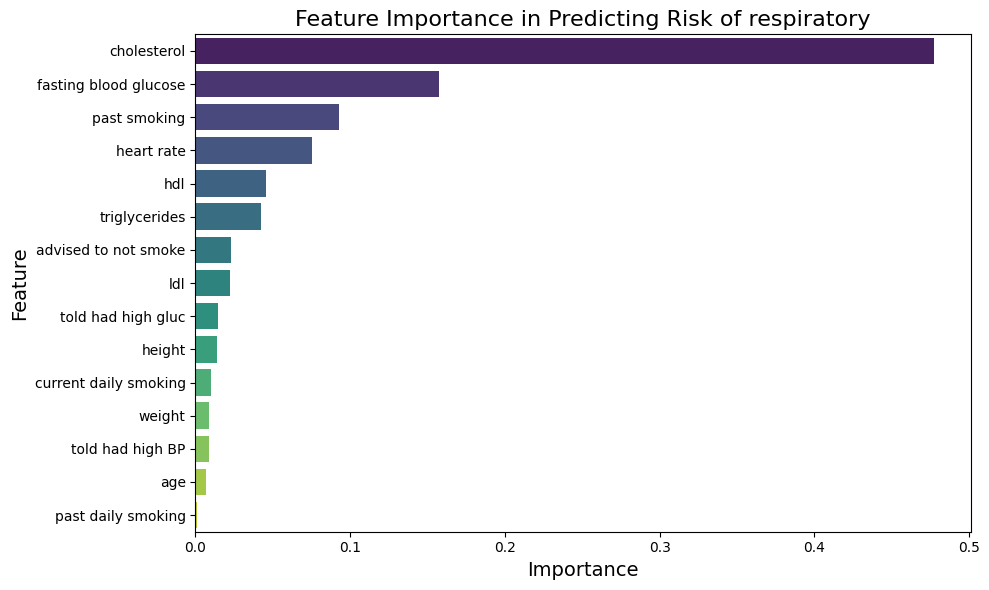

Feature Importance (sorted):
                  Feature  Importance
1             cholesterol       0.477
4   fasting blood glucose       0.158
13           past smoking       0.093
0              heart rate       0.075
2                     hdl       0.046
5           triglycerides       0.042
14   advised to not smoke       0.023
3                     ldl       0.022
10     told had high gluc       0.015
7                  height       0.014
11  current daily smoking       0.010
8                  weight       0.009
9        told had high BP       0.009
6                     age       0.007
12     past daily smoking       0.001


In [ ]:
# Import necessary libraries
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load your dataset (replace with the actual path to your file)
# df_ncd = pd.read_csv('path_to_your_data.csv')  # Replace with the correct path

# Example: Define features and target (make sure these match your dataset columns)
features = ['heart rate', 'cholesterol', 'hdl', 'ldl', 'fasting blood glucose', 'triglycerides', 'age', 'height', 'weight',
            'told had high BP', 'told had high gluc', 'current daily smoking', 'past daily smoking', 'past smoking',
            'advised to not smoke']


# Step 2: Separate features (X) and target variable (y)
X = df_ncd[features]  # Select features
y = df_ncd['Risk of respiratory']  # Assuming 'Risk of CVD' is your target column

# Step 3: Split the data into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Step 4: Train a decision tree classifier
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)

# Step 5: Get feature importances
importances = clf.feature_importances_

# Step 6: Create a DataFrame to view feature importance
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
})

# Step 7: Sort the features by importance
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Step 8: Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('Feature Importance in Predicting Risk of respiratory', fontsize=16)
plt.xlabel('Importance', fontsize=14)
plt.ylabel('Feature', fontsize=14)
plt.tight_layout()
plt.show()

# Print the sorted importance values
print("Feature Importance (sorted):")
print(importance_df)


In [ ]:
#Smote

In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import LabelEncoder

# Step 1: Encode the 'Risk of respiratory' categories to integers
le = LabelEncoder()
df_ncd['Risk of respiratory Encoded'] = le.fit_transform(df_ncd['Risk of respiratory'])

# Step 2: Separate features and target
X = df_ncd[selected_features]
y = df_ncd['Risk of respiratory Encoded']

# Step 3: Apply SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Step 4: Decode the target back to the original categories
y_resampled_decoded = le.inverse_transform(y_resampled)

# Step 5: Create a new DataFrame with the resampled data
df_resampled = pd.DataFrame(X_resampled, columns=selected_features)
df_resampled['Risk of respiratory'] = y_resampled_decoded

# Check the distribution of the target variable after SMOTE
print("Distribution of 'Risk of respiratory' after SMOTE:")
print(df_resampled['Risk of respiratory'].value_counts())

# Optional: Save or proceed with the resampled data for further analysis


Distribution of 'Risk of respiratory' after SMOTE:
Risk of respiratory
Medium    4073
Low       4073
High      4073
Name: count, dtype: int64


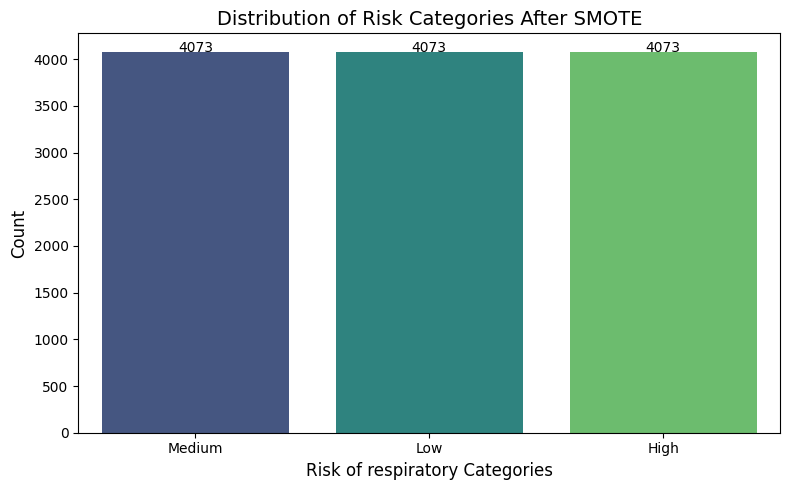

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the occurrences of each risk category after SMOTE
risk_counts = df_resampled['Risk of respiratory'].value_counts()

# Plot the bar graph
plt.figure(figsize=(8, 5))
sns.barplot(x=risk_counts.index, y=risk_counts.values, palette='viridis')

# Add titles and labels
plt.title('Distribution of Risk Categories After SMOTE', fontsize=14)
plt.xlabel('Risk of respiratory Categories', fontsize=12)
plt.ylabel('Count', fontsize=12)

# Show values on top of the bars
for i, value in enumerate(risk_counts.values):
    plt.text(i, value + 5, str(value), ha='center', fontsize=10)

# Display the plot
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Step 1: Prepare the data
X = df_resampled[selected_features]
y = df_resampled['Risk of respiratory']

# Encode the target variable (if not already encoded)
y_encoded = le.fit_transform(y)  # Using the same LabelEncoder as before

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

# Step 2: Initialize models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100),
    'Support Vector Machine': SVC(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5)
}

# Step 3: Initialize dictionary to store results
results = {}

# Train and evaluate each model
for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Get classification metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)

    # Extract Precision, Recall, F1-Score for each model class
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']

    # Store results in the dictionary
    results[model_name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1_score,
        'Confusion Matrix': confusion_matrix(y_test, y_pred)
    }

# Step 4: Convert results dictionary to DataFrame
results_df = pd.DataFrame(results).T  # Transpose for easier viewing

# Print results
print(results_df)


                       Accuracy Precision Recall F1-Score  \
Logistic Regression       0.953     0.953  0.953    0.952   
Random Forest             0.977     0.977  0.977    0.977   
Support Vector Machine    0.899     0.899  0.899    0.899   
Decision Tree             0.955     0.955  0.955    0.955   
K-Nearest Neighbors       0.923     0.923  0.923    0.923   

                                                    Confusion Matrix  
Logistic Regression     [[801, 1, 12], [12, 762, 41], [16, 34, 765]]  
Random Forest              [[813, 0, 1], [2, 791, 22], [8, 23, 784]]  
Support Vector Machine  [[801, 0, 13], [6, 695, 114], [25, 89, 701]]  
Decision Tree             [[809, 2, 3], [6, 770, 39], [13, 46, 756]]  
K-Nearest Neighbors       [[814, 0, 0], [5, 725, 85], [19, 78, 718]]  


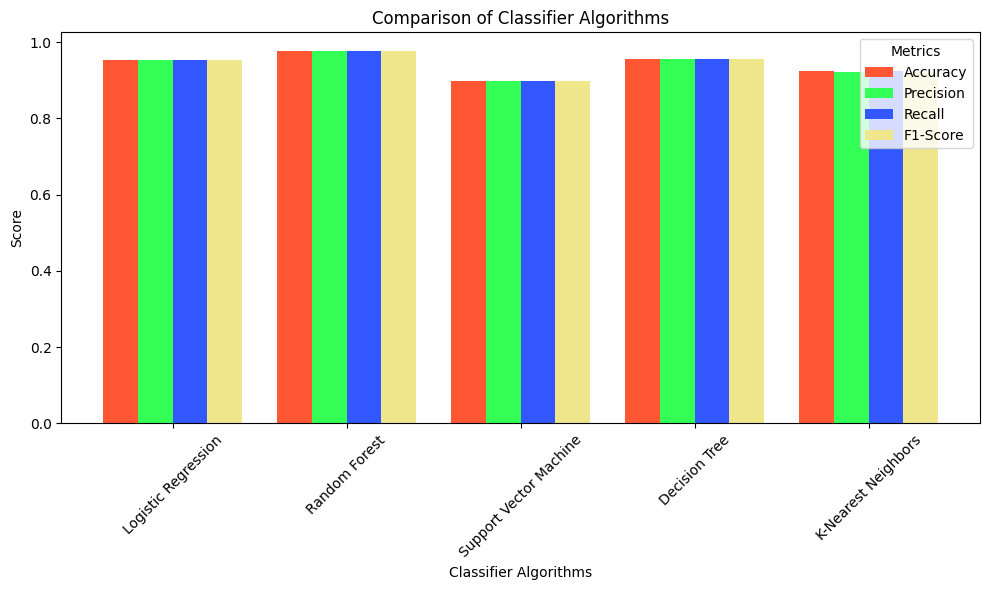

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Step 1: Prepare the data
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

# Create a DataFrame from the results for easier plotting
metrics_df = results_df[metrics]

# Define colors for each metric
colors = ['#FF5733', '#33FF57', '#3357FF', '#F0E68C']

# Step 2: Plot the comparison of classifiers using bar graphs with different colors for each metric
plt.figure(figsize=(10, 6))

# Loop through each metric and plot its bars with different colors
bar_width = 0.2  # Set the width of the bars
index = np.arange(len(metrics_df))  # Position for each classifier

for i, metric in enumerate(metrics):
    plt.bar(index + i * bar_width, metrics_df[metric], bar_width, label=metric, color=colors[i])

# Add labels and title
plt.xlabel('Classifier Algorithms')
plt.ylabel('Score')
plt.title('Comparison of Classifier Algorithms')

# Adjust x-ticks to be centered and show classifier names
plt.xticks(index + bar_width * 1.5, metrics_df.index, rotation=45)

# Add legend
plt.legend(title='Metrics')

# Tight layout to prevent overlapping labels
plt.tight_layout()

# Show plot
plt.show()


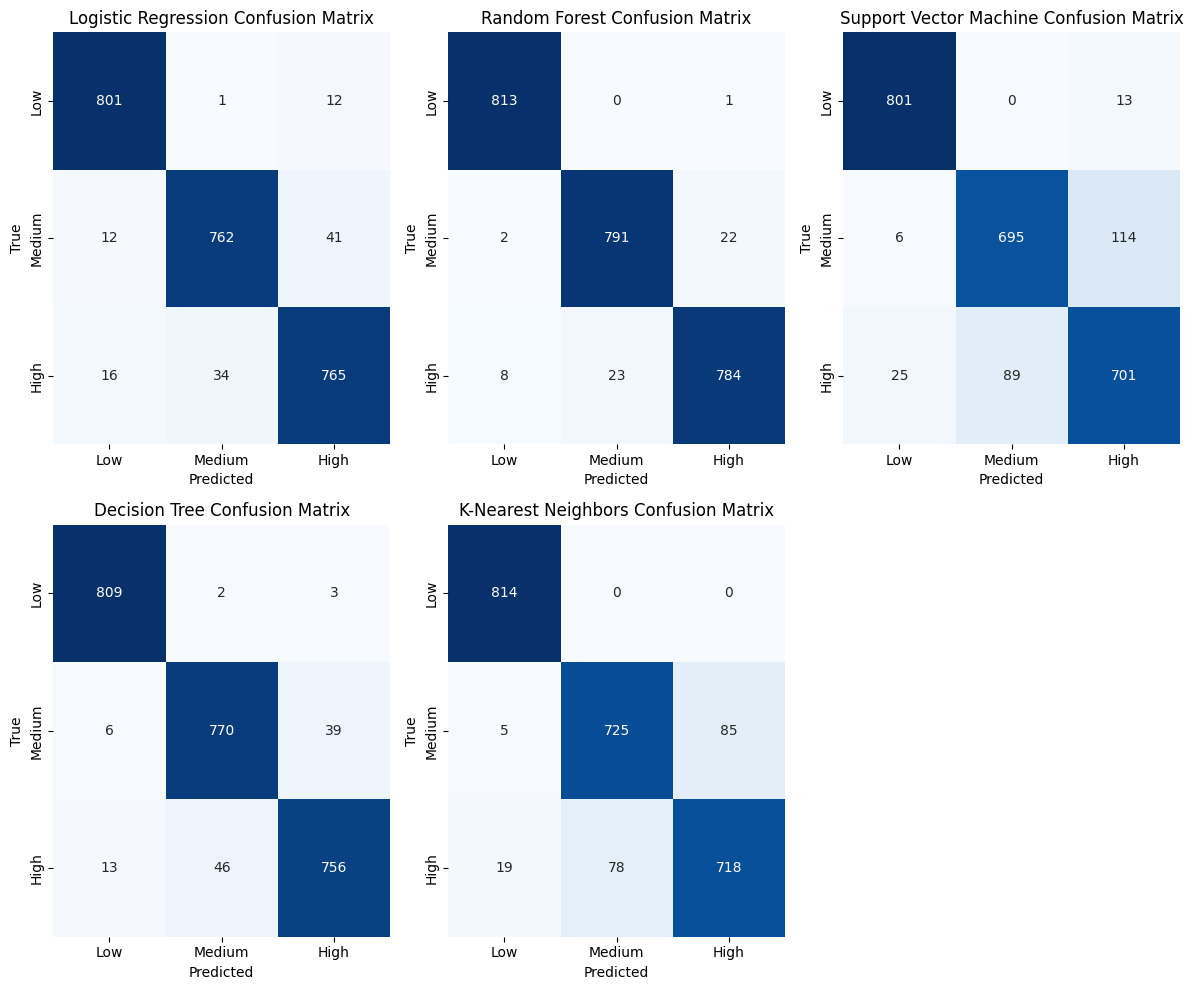

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Step 1: Plot the confusion matrix for each model
plt.figure(figsize=(12, 10))

# Iterate through models and plot their confusion matrix
for i, (model_name, result) in enumerate(results.items()):
    cm = result['Confusion Matrix']

    plt.subplot(2, 3, i + 1)  # Create subplots (2 rows, 3 columns)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Low', 'Medium', 'High'], yticklabels=['Low', 'Medium', 'High'])
    plt.title(f'{model_name} Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')

plt.tight_layout()
plt.show()


In [ ]:
#GridSearch

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Define models and hyperparameter grids for GridSearchCV
models = {
    'Random Forest': RandomForestClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Support Vector Machine': SVC(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier()
}

param_grids = {
    'Random Forest': {
        'n_estimators': [50, 100, 200],
        'max_depth': [10, 20, 30, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'bootstrap': [True, False]
    },
    'Logistic Regression': {
        'C': [0.1, 1, 10],
        'solver': ['lbfgs', 'liblinear'],
        'penalty': ['l2']
    },
    'Support Vector Machine': {
        'C': [0.1, 1, 10],
        'kernel': ['linear', 'rbf'],
        'gamma': ['scale', 'auto']
    },
    'Decision Tree': {
        'max_depth': [10, 20, 30, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    },
    'K-Nearest Neighbors': {
        'n_neighbors': [3, 5, 7, 10],
        'weights': ['uniform', 'distance'],
        'metric': ['euclidean', 'manhattan']
    }
}

# Hyperparameter tuning with GridSearchCV
best_models_grid = {}

for model_name, model in models.items():
    print(f"Performing GridSearchCV for {model_name}...")

    grid_search = GridSearchCV(estimator=model, param_grid=param_grids[model_name], cv=5, n_jobs=-1, verbose=1)
    grid_search.fit(X_train, y_train)

    best_models_grid[model_name] = grid_search.best_estimator_
    print(f"Best parameters for {model_name}: {grid_search.best_params_}\n")

# Step 2: Evaluate the best models
for model_name, model in best_models_grid.items():
    print(f"Evaluating {model_name} after GridSearchCV...")
    y_pred = model.predict(X_test)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("\n")


Performing GridSearchCV for Random Forest...
Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best parameters for Random Forest: {'bootstrap': False, 'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Performing GridSearchCV for Logistic Regression...
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters for Logistic Regression: {'C': 10, 'penalty': 'l2', 'solver': 'liblinear'}

Performing GridSearchCV for Support Vector Machine...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters for Support Vector Machine: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}

Performing GridSearchCV for Decision Tree...
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters for Decision Tree: {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2}

Performing GridSearchCV for K-Nearest Neighbors...
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters fo